# RiskLens: Analyzing the Evolution of Corporate Risk Disclosures
**Question:** *What meaningfully changed in this company's disclosed risks compared with its previous annual filing?*

**Important:** this notebook measures changes in **disclosure language**, not changes in underlying economic risk. A wording difference is not automatically a material change.

**How to run:** Runtime > Run all (CPU is enough). The first run downloads each yearly EDGAR-CORPUS split one at a time (~1.5 GB each, slow); only `section_1A` of ~49 companies is kept in a small JSON cache, so re-runs are fast. If Colab asks you to restart after the `datasets==3.6.0` install, restart and run all again.

**Decisions made for you:** (1) P&G's CIK is **80424**; the brief's 804328 is Qualcomm, so it was corrected (Qualcomm is a Technology replacement). (2) A filing is valid only if `section_1A` has >= 3,000 characters and >= 500 words and is not just 'incorporated by reference'. (3) Missing filings are never invented or replaced by another year. (4) There are **no category labels** in the dataset: labels come from a keyword lexicon (weak labels) plus a model, and a human-annotation sample is exported for real validation.

| Cell | What it does |
|---|---|
| 1 | Install/pin `datasets`, imports, config, company lists, helpers |
| 2 | Load years one at a time, validate `section_1A`, availability check, replacements, final sample |
| 3 | Clean text, sentence segmentation, boilerplate flagging |
| 4 | Year-over-year matching (exact + TF-IDF cosine), change types, synthetic matcher test |
| 5 | Risk categories, grouped-CV evaluation, subgroup audit, explainability |
| 6 | Industry/year comparison, figures, exports, annotation sample |
| 7 | Optional human-label scoring, model card, pitch outline, file summary |

### Cell 1 - Setup
Pins `datasets==3.6.0` only if needed, defines settings, candidate and replacement companies, and helper functions.

In [ ]:
# ============================================================
# CELL 1 - SETUP, CONFIGURATION, COMPANY LISTS AND HELPERS
# ============================================================
import importlib, importlib.metadata as md, subprocess, sys

REQUIRED_DATASETS = "3.6.0"          # last version that still supports the EDGAR-CORPUS loading script
try:
    _installed = md.version("datasets")
except md.PackageNotFoundError:
    _installed = None
if _installed != REQUIRED_DATASETS:  # install only when needed (avoids repeated installs)
    print(f"Installing datasets=={REQUIRED_DATASETS} (found: {_installed}) ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", f"datasets=={REQUIRED_DATASETS}"])
    importlib.invalidate_caches()
    if "datasets" in sys.modules:
        raise RuntimeError("`datasets` was changed after being imported. Use Runtime > Restart session, "
                           "then run all cells again from the top (the HF cache is kept).")

import os, re, gc, json, time, math, random, shutil, zipfile, warnings
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 90)

# ---------------- configuration ----------------
SEED = 42
random.seed(SEED); np.random.seed(SEED)
DATASET = "eloukas/edgar-corpus"
YEARS = [2015, 2016, 2017, 2018, 2019, 2020]
N_PER_SECTOR = 5
USE_DRIVE = False        # True -> outputs/caches are stored in Google Drive and survive runtime resets
DOWNLOAD_ZIP = False     # True -> browser downloads the zip of all outputs at the very end

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = Path("/content/drive/MyDrive/risklens_outputs")
else:
    OUT = Path("/content/risklens_outputs")
CACHE_DIR = OUT / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# filing validity rules for section_1A
MIN_CHARS, MIN_WORDS = 3000, 500
MIN_SENTENCES = 15                 # after sentence segmentation (checked in Cell 3)
# sentence-matching thresholds (explained in Cell 4)
SIM_FLOOR, REWRITE_MIN, MINOR_MIN = 0.50, 0.60, 0.90
BOILER_MIN_COMPANIES = 3           # an identical sentence in >= 3 different companies = boilerplate

# ---------------- company lists ----------------
# NOTE: P&G's CIK is 80424. The CIK in the brief (804328) belongs to Qualcomm, so it was corrected here
# and Qualcomm (804328) is kept as a Technology replacement.
CANDIDATES = {
    "Technology": [("Microsoft","789019"),("IBM","51143"),("Intel","50863"),("Oracle","1341439"),("Cisco","858877")],
    "Financial Services": [("JPMorgan Chase","19617"),("Bank of America","70858"),("Visa","1403161"),
                           ("Mastercard","1141391"),("Goldman Sachs","886982")],
    "Consumer Goods": [("Coca-Cola","21344"),("PepsiCo","77476"),("Procter & Gamble","80424"),
                       ("Nike","320187"),("McDonald's","63908")],
    "Healthcare": [("Johnson & Johnson","200406"),("Merck","310158"),("Abbott Laboratories","1800"),
                   ("Pfizer","78003"),("AbbVie","1551152")],
}
REPLACEMENTS = {   # tried in this order, only if a candidate fails the availability check
    "Technology": [("Apple","320193"),("Texas Instruments","97476"),("Qualcomm","804328"),("Adobe","796343"),
                   ("Nvidia","1045810"),("HP Inc","47217"),("Micron","723125")],
    "Financial Services": [("Citigroup","831001"),("Wells Fargo","72971"),("Morgan Stanley","895421"),
                           ("American Express","4962"),("Capital One","927628"),("U.S. Bancorp","36104"),("PNC","713676")],
    "Consumer Goods": [("Colgate-Palmolive","21665"),("Kimberly-Clark","55785"),("Mondelez","1103982"),
                       ("Starbucks","829224"),("Walmart","104169"),("Target","27419"),("Costco","909832"),("Home Depot","354950")],
    "Healthcare": [("Eli Lilly","59478"),("Bristol-Myers Squibb","14272"),("Amgen","318154"),("Gilead","882095"),
                   ("Medtronic","1613103"),("UnitedHealth","731766"),("Baxter","10456")],
}
SECTORS = list(CANDIDATES)
ORDERED = {s: [c for _, c in CANDIDATES[s]] + [c for _, c in REPLACEMENTS[s]] for s in SECTORS}
CIK_INFO = {}
for s in SECTORS:
    for role, lst in (("candidate", CANDIDATES[s]), ("replacement", REPLACEMENTS[s])):
        for name, cik in lst:
            assert cik not in CIK_INFO, f"Duplicate CIK in company lists: {cik}"
            CIK_INFO[cik] = (name, s, role)

# ---------------- helpers ----------------
def norm_cik(x):
    try: return str(int(str(x).strip()))
    except Exception: return ""

def norm_key(s):
    """lower-case, strip punctuation, collapse spaces -> used for exact sentence matching"""
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]", " ", s.lower())).strip()

INCORP_RE = re.compile(r"incorporated (herein )?by reference|see .{0,60}(item 7|annual report|management.s discussion)", re.I)
def validate_text(t):
    """Return 'ok' or the reason why a section_1A field is NOT usable."""
    if t is None or not isinstance(t, str): return "missing"
    s = " ".join(t.split())
    if not s: return "empty"
    if len(s) < MIN_CHARS: return "incorporated_by_reference" if INCORP_RE.search(s) else "too_short"
    if len(s.split()) < MIN_WORDS: return "too_short"
    return "ok"

def savefig(name):
    plt.tight_layout(); plt.savefig(OUT / name, dpi=150, bbox_inches="tight"); plt.show()

print(f"Setup OK | datasets=={md.version('datasets')} | outputs -> {OUT}")
print(f"Candidate companies: {sum(len(v) for v in CANDIDATES.values())} | replacements: {sum(len(v) for v in REPLACEMENTS.values())}")

Installing datasets==3.6.0 (found: 4.8.5) ...
Setup OK | datasets==3.6.0 | outputs -> /content/risklens_outputs
Candidate companies: 20 | replacements: 29


### Cell 2 - Data loading, validation and sample selection
Processes 2015-2020 sequentially (one yearly dataset in memory at a time), caches only the needed rows, checks every company-year, tries replacements in the same sector, and reports exact gaps. If 5 x 4 x 6 is impossible it picks the best valid alternative window and says so.

In [ ]:
# ============================================================
# CELL 2 - LOAD EDGAR-CORPUS YEAR BY YEAR, VALIDATE section_1A, SELECT SAMPLE
# ============================================================
import datasets as hfd
from datasets import load_dataset
assert hfd.__version__ == REQUIRED_DATASETS, f"Need datasets=={REQUIRED_DATASETS}, got {hfd.__version__}. Restart runtime."

WANTED = set(CIK_INFO)

def extract_year(year):
    """Load ONE yearly config, keep only section_1A of our (candidate + replacement) CIKs, free memory.
    Results are cached as small JSON so a re-run does not touch the 1.5 GB dataset again."""
    cache_file = CACHE_DIR / f"sec1A_{year}.json"
    if cache_file.exists():
        print(f"[{year}] using small local cache {cache_file.name}")
        return json.loads(cache_file.read_text())
    t0 = time.time()
    print(f"[{year}] loading year_{year} (Hugging Face cache is reused if it exists) ...")
    try:
        ds = load_dataset(DATASET, f"year_{year}", split="train", trust_remote_code=True)
        n_total = len(ds)
        idx = [i for i, c in enumerate(ds["cik"]) if norm_cik(c) in WANTED]
        rows = []
        if idx:
            sub = ds.select(idx).select_columns(["cik", "filename", "section_1A"])
            rows = [{"cik": norm_cik(r["cik"]), "filename": r["filename"], "section_1A": r["section_1A"]} for r in sub]
            del sub
        del ds; gc.collect()
        data = {"year": year, "n_records": n_total, "rows": rows}
        cache_file.write_text(json.dumps(data))
        print(f"[{year}] {n_total} records scanned, {len(rows)} rows kept ({time.time()-t0:.0f}s)")
        return data
    except Exception as e:                       # do not crash the whole notebook for one bad year
        gc.collect()
        print(f"[{year}] FAILED to load: {type(e).__name__}: {str(e)[:200]}")
        return {"year": year, "error": str(e), "rows": []}

# ---- 1) sequential extraction (never more than one yearly dataset in memory) ----
year_data = {y: extract_year(y) for y in YEARS}
assert any(not d.get("error") for d in year_data.values()), "No yearly split could be loaded - check internet / datasets version."

# ---- 2) validate every (company, year) ----
status, best_text = {}, {}
for y, d in year_data.items():
    by_cik = defaultdict(list)
    for r in d["rows"]: by_cik[r["cik"]].append(r)
    for cik in WANTED:
        rows = by_cik.get(cik, [])
        if d.get("error"):  status[(cik, y)] = "year_load_failed"; continue
        if not rows:        status[(cik, y)] = "not_in_year_split"; continue
        chosen = max(rows, key=lambda r: len(r["section_1A"] or ""))     # if duplicates exist keep the longest
        status[(cik, y)] = validate_text(chosen["section_1A"])
        if status[(cik, y)] == "ok": best_text[(cik, y)] = chosen["section_1A"]
del year_data; gc.collect()

avail = pd.DataFrame([{"sector": CIK_INFO[c][1], "company": CIK_INFO[c][0], "cik": c, "role": CIK_INFO[c][2],
                       **{str(y): status[(c, y)] for y in YEARS}} for c in WANTED])
avail["years_ok"] = avail[[str(y) for y in YEARS]].apply(lambda r: sum(v == "ok" for v in r), axis=1)
avail = avail.sort_values(["sector", "role", "company"]).reset_index(drop=True)
avail.to_csv(OUT / "availability_matrix.csv", index=False)
print("\nAvailability of the ORIGINAL candidate companies (ok = usable section_1A):")
display(avail[avail.role == "candidate"][["sector", "company", "cik"] + [str(y) for y in YEARS] + ["years_ok"]])

# ---- 3) choose the sample ----
def ok_years(cik): return {y for y in YEARS if status.get((cik, y)) == "ok"}
def pick(window):
    return {s: [c for c in ORDERED[s] if set(window) <= ok_years(c)][:N_PER_SECTOR] for s in SECTORS}

TARGET = len(SECTORS) * N_PER_SECTOR * len(YEARS)
WINDOW = list(YEARS); PICKED = pick(WINDOW)
if all(len(PICKED[s]) == N_PER_SECTOR for s in SECTORS):
    print(f"\nFULL TARGET MET: {N_PER_SECTOR} companies x {len(SECTORS)} sectors x {len(YEARS)} years = {TARGET} filings.")
else:
    print("\nFULL TARGET NOT MET for 2015-2020. Gaps (sector -> companies with usable filings in ALL six years):")
    for s in SECTORS: print(f"  {s}: {len(PICKED[s])}/{N_PER_SECTOR} -> {[CIK_INFO[c][0] for c in PICKED[s]]}")
    best = None                                   # best valid alternative = most filings, over contiguous year windows
    for a in YEARS:
        for b in YEARS:
            if b - a >= 1:
                w = list(range(a, b + 1)); p = pick(w)
                score = (sum(len(p[s]) >= 2 for s in SECTORS), sum(len(p[s]) for s in SECTORS) * len(w), len(w))
                if best is None or score > best[0]: best = (score, w, p)
    _, WINDOW, PICKED = best
    print(f"  -> Best valid alternative: years {WINDOW[0]}-{WINDOW[-1]}, companies per sector: "
          f"{ {s: len(PICKED[s]) for s in SECTORS} }")

gaps = [{"sector": CIK_INFO[c][1], "company": CIK_INFO[c][0], "cik": c, "year": y, "status": status[(c, y)]}
        for s in SECTORS for _, c in CANDIDATES[s] for y in YEARS if status[(c, y)] != "ok"]
pd.DataFrame(gaps).to_csv(OUT / "candidate_gaps.csv", index=False)

rows = []
for s in SECTORS:
    for c in PICKED[s]:
        for y in WINDOW:
            rows.append({"cik": c, "company": CIK_INFO[c][0], "sector": s, "role": CIK_INFO[c][2], "year": y,
                         "text": best_text[(c, y)]})
SAMPLE = pd.DataFrame(rows)
del best_text; gc.collect()

assert len(SAMPLE) > 0 and len(WINDOW) >= 2, "No company has usable consecutive-year filings."
assert sum(len(PICKED[s]) >= 1 for s in SECTORS) >= 2, "Need at least 2 sectors with data for a subgroup comparison."
SAMPLE.drop(columns="text").assign(n_chars=SAMPLE.text.str.len()).to_csv(OUT / "sample_manifest.csv", index=False)
print(f"\nCOLLECTED {len(SAMPLE)} company-year filings (original target = {TARGET}). "
      f"Companies per sector: { {s: len(PICKED[s]) for s in SECTORS} }; years {WINDOW[0]}-{WINDOW[-1]}.")
print("Replacements used:", [CIK_INFO[c][0] for s in SECTORS for c in PICKED[s] if CIK_INFO[c][2] == "replacement"] or "none")

[2015] loading year_2015 (Hugging Face cache is reused if it exists) ...


README.md:   0%|          | 0.00/43.7k [00:00<?, ?B/s]

edgar-corpus.py:   0%|          | 0.00/4.64k [00:00<?, ?B/s]

2015/train.jsonl: reconstructing file:   0%|          |  0.00B / 1.49GB            

2015/train.jsonl: downloading bytes:           |  0.00B            

...

Generating validation split:   0%|          | 0/686 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/685 [00:00<?, ? examples/s]

[2020] 5480 records scanned, 36 rows kept (78s)

Availability of the ORIGINAL candidate companies (ok = usable section_1A):


,sector,company,cik,2015,2016,2017,2018,2019,2020,years_ok
0,Consumer Goods,Coca-Cola,21344,ok,ok,ok,ok,ok,ok,6
1,Consumer Goods,McDonald's,63908,ok,ok,ok,not_in_year_split,not_in_year_split,not_in_year_split,3
2,Consumer Goods,Nike,320187,ok,ok,ok,ok,ok,ok,6
3,Consumer Goods,PepsiCo,77476,ok,not_in_year_split,ok,not_in_year_split,ok,ok,4
4,Consumer Goods,Procter & Gamble,80424,ok,not_in_year_split,ok,ok,ok,ok,5
13,Financial Services,Bank of America,70858,ok,ok,ok,not_in_year_split,ok,ok,5
14,Financial Services,Goldman Sachs,886982,not_in_year_split,not_in_year_split,not_in_year_split,ok,ok,ok,3
15,Financial Services,JPMorgan Chase,19617,ok,ok,ok,ok,not_in_year_split,ok,5
16,Financial Services,Mastercard,1141391,ok,ok,ok,ok,ok,ok,6
17,Financial Services,Visa,1403161,ok,ok,ok,not_in_year_split,ok,ok,5



FULL TARGET NOT MET for 2015-2020. Gaps (sector -> companies with usable filings in ALL six years):
  Technology: 3/5 -> ['Microsoft', 'Qualcomm', 'HP Inc']
  Financial Services: 2/5 -> ['Mastercard', 'American Express']
  Consumer Goods: 3/5 -> ['Coca-Cola', 'Nike', 'Colgate-Palmolive']
  Healthcare: 0/5 -> []
  -> Best valid alternative: years 2016-2020, companies per sector: {'Technology': 5, 'Financial Services': 3, 'Consumer Goods': 3, 'Healthcare': 2}

COLLECTED 65 company-year filings (original target = 120). Companies per sector: {'Technology': 5, 'Financial Services': 3, 'Consumer Goods': 3, 'Healthcare': 2}; years 2016-2020.
Replacements used: ['Apple', 'Qualcomm', 'Nvidia', 'HP Inc', 'American Express', 'PNC', 'Colgate-Palmolive', 'Gilead']


### Cell 3 - Cleaning, sentence segmentation and boilerplate
Rule-based sentence splitter (no downloads). Sentences identical in 3 or more different companies are flagged as boilerplate and excluded from change detection.

In [ ]:
# ============================================================
# CELL 3 - CLEAN section_1A, SPLIT INTO SENTENCES, FLAG BOILERPLATE
# ============================================================
DOT = "§§"
ABBR = ["U.S.", "U.K.", "E.U.", "Inc.", "Corp.", "Co.", "Ltd.", "L.P.", "No.", "Nos.", "Mr.", "Ms.", "Dr.",
        "vs.", "etc.", "e.g.", "i.e.", "St.", "Jr.", "Sr.", "approx.", "Fig."]
SPLIT_RE = re.compile(r'(?:(?<=[.!?])|(?<=[.!?]["”’)]))\s+(?=[A-Z“"(\[])')

def clean_section(t):
    t = t.replace("\u00a0", " ")
    t = re.sub(r"\s+", " ", t).strip()
    t = re.sub(r"(?i)table of contents", " ", t)
    t = re.sub(r"(?i)^\s*item\s*1a\.?\s*[-–—:]?\s*risk factors\.?", "", t)
    m = re.search(r"(?i)item\s*1b\.?\s*unresolved staff comments", t)
    if m and m.start() > 0.5 * len(t): t = t[:m.start()]          # drop the next section if it leaked in
    t = re.sub(r"[•●▪■◦]", ". ", t)                                  # bullets act as sentence boundaries
    return t

def split_sentences(t):
    for a in ABBR: t = t.replace(a, a.replace(".", DOT))            # protect abbreviations
    out = []
    for s in SPLIT_RE.split(t):
        s = s.replace(DOT, ".").strip(" .;:-")
        w = s.split()
        if not (8 <= len(w) <= 250): continue                        # too short = heading/fragment, too long = parsing error
        letters = sum(ch.isalpha() for ch in s)
        if letters / max(1, len(s.replace(" ", ""))) < 0.6: continue  # mostly numbers/symbols = table debris
        out.append(s + ".")
    return out

# ---- build the sentence table (one row per unique sentence per filing) ----
recs = []
for r in SAMPLE.itertuples(index=False):
    seen = set()
    for i, s in enumerate(split_sentences(clean_section(r.text))):
        k = norm_key(s)
        if k in seen: continue                                       # remove duplicates inside one filing
        seen.add(k)
        recs.append((f"{r.cik}_{r.year}_{i}", r.cik, r.company, r.sector, r.year, i, s, k, len(s.split())))
sent_df = pd.DataFrame(recs, columns=["sentence_id", "cik", "company", "sector", "year", "sent_idx", "text", "norm_key", "n_words"])
del recs; gc.collect()

# ---- drop filings that did not yield enough sentences (probably broken text); drop whole company to keep consecutive years ----
cnt = sent_df.groupby(["cik", "year"]).size()
bad_ciks = sorted({c for (c, y), n in cnt.items() if n < MIN_SENTENCES} |
                  {c for c in SAMPLE.cik.unique() for y in WINDOW if (c, y) not in cnt.index})
if bad_ciks:
    print("WARNING - dropping companies with a filing that has <", MIN_SENTENCES, "usable sentences:",
          [CIK_INFO[c][0] for c in bad_ciks])
    sent_df = sent_df[~sent_df.cik.isin(bad_ciks)].reset_index(drop=True)
    SAMPLE = SAMPLE[~SAMPLE.cik.isin(bad_ciks)].reset_index(drop=True)
assert len(sent_df) > 0 and sent_df.groupby("sector").cik.nunique().ge(1).sum() >= 2, "Too little usable text after cleaning."

# ---- boilerplate: identical (normalised) sentence used by >= 3 different companies ----
n_comp = sent_df.groupby("norm_key")["cik"].nunique()
boiler_keys = set(n_comp[n_comp >= BOILER_MIN_COMPANIES].index)
sent_df["is_boilerplate"] = sent_df.norm_key.isin(boiler_keys)

filing_stats = (sent_df.groupby(["sector", "company", "cik", "year"])
                .agg(n_sentences=("text", "size"), n_boilerplate=("is_boilerplate", "sum"), mean_words=("n_words", "mean"))
                .reset_index())
filing_stats["pct_boilerplate"] = (100 * filing_stats.n_boilerplate / filing_stats.n_sentences).round(1)
filing_stats.to_csv(OUT / "filing_stats.csv", index=False)

# one clean text per filing (non-boilerplate) - used for document-level similarity
filing_docs = {k: " ".join(g.text) for k, g in sent_df[~sent_df.is_boilerplate].groupby(["cik", "year"])}
SAMPLE = SAMPLE.drop(columns="text"); gc.collect()      # raw text no longer needed -> free memory

print(f"{len(sent_df):,} sentences from {len(filing_stats)} filings | boilerplate sentences flagged: "
      f"{int(sent_df.is_boilerplate.sum()):,} ({100*sent_df.is_boilerplate.mean():.1f}%)")
display(filing_stats.groupby("sector")[["n_sentences", "pct_boilerplate", "mean_words"]].mean().round(1))

20,727 sentences from 65 filings | boilerplate sentences flagged: 0 (0.0%)


,n_sentences,pct_boilerplate,mean_words
sector,,,
Consumer Goods,261.8,0.0,33.6
Financial Services,397.5,0.0,30.1
Healthcare,316.9,0.0,30.2
Technology,306.8,0.0,31.7


### Cell 4 - Change detection between consecutive years
Exact matches first, then TF-IDF cosine matching of the rest. Includes a **synthetic test with known edits** to measure how well the matcher recovers them, split by sector and sentence length.

In [ ]:
# ============================================================
# CELL 4 - YEAR-OVER-YEAR SENTENCE MATCHING + CHANGE DETECTION + SYNTHETIC VALIDATION
# ------------------------------------------------------------
# Per consecutive pair (year t-1 -> t) of one company:
#   1. EXACT match      : identical normalised sentence                -> 'unchanged'
#   2. APPROXIMATE match: TF-IDF (1-2 grams) cosine, one-to-one greedy -> sim>=0.90 'minor_edit', 0.60-0.90 'rewritten'
#   3. No match >= 0.60 in the other year                              -> 'added' (new in t) / 'removed' (gone from t-1)
# Boilerplate sentences are excluded. These labels describe WORDING changes, not business materiality.
# ============================================================
STOP = set(ENGLISH_STOP_WORDS)
NUM_RE = re.compile(r"\$?\d[\d,\.]*%?")
SIGNAL = {"material", "materially", "significant", "significantly", "substantial", "adversely", "adverse", "severe",
          "may", "could", "might", "would", "will", "not", "no", "cannot", "unable", "increase", "increased", "decline"}
tok = lambda s: re.findall(r"[a-z][a-z\-]+", s.lower())

def match_pair(prev, curr, floor=SIM_FLOOR):
    """prev/curr: lists of (norm_key, text). Returns exact matches, greedy 1-to-1 approximate pairs (sim>=floor)
    and nearest-neighbour info for every sentence without an exact match."""
    pk = {k: i for i, (k, _) in enumerate(prev)}
    exact = {i: pk[k] for i, (k, _) in enumerate(curr) if k in pk}
    used_p = set(exact.values())
    rc = [i for i in range(len(curr)) if i not in exact]
    rp = [j for j in range(len(prev)) if j not in used_p]
    pairs, nn_c, nn_p = [], {}, {}
    if rc and rp:
        tc, tp = [curr[i][1] for i in rc], [prev[j][1] for j in rp]
        vec = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), sublinear_tf=True)
        try:
            vec.fit(tc + tp); S = (vec.transform(tc) @ vec.transform(tp).T).tocsr()
        except ValueError:
            return {"exact": exact, "pairs": pairs, "nn_c": nn_c, "nn_p": nn_p, "rc": rc, "rp": rp}
        mc, ac = S.max(axis=1).toarray().ravel(), np.asarray(S.argmax(axis=1)).ravel()
        mp, ap = S.max(axis=0).toarray().ravel(), np.asarray(S.argmax(axis=0)).ravel()
        for a, i in enumerate(rc): nn_c[i] = (min(1.0, float(mc[a])), rp[ac[a]])
        for b, j in enumerate(rp): nn_p[j] = (min(1.0, float(mp[b])), rc[ap[b]])
        co = S.tocoo(); m = co.data >= floor
        order = np.argsort(-co.data[m]); r_, c_, d_ = co.row[m][order], co.col[m][order], co.data[m][order]
        ua, ub = set(), set()
        for a, b, s in zip(r_, c_, d_):                  # strongest pairs first -> each sentence used once
            if a in ua or b in ub: continue
            ua.add(a); ub.add(b); pairs.append((rc[a], rp[b], min(1.0, float(s))))
    return {"exact": exact, "pairs": pairs, "nn_c": nn_c, "nn_p": nn_p, "rc": rc, "rp": rp}

def term_flags(prev_t, curr_t):
    ta, tb = set(tok(prev_t)) - STOP, set(tok(curr_t)) - STOP
    sa, sb = set(tok(prev_t)) & SIGNAL, set(tok(curr_t)) & SIGNAL
    return (", ".join(sorted(tb - ta)[:8]), ", ".join(sorted(ta - tb)[:8]),
            set(NUM_RE.findall(prev_t)) != set(NUM_RE.findall(curr_t)), ", ".join(sorted(sa ^ sb)))

changes, yoy, sens = [], [], []
usable = sent_df[~sent_df.is_boilerplate]
for cik, g in usable.groupby("cik"):
    meta = g.iloc[0]
    years = sorted(g.year.unique())
    for y0, y1 in zip(years[:-1], years[1:]):
        if y1 - y0 != 1: continue                                   # only strictly consecutive filings
        P = g[g.year == y0].reset_index(drop=True); C = g[g.year == y1].reset_index(drop=True)
        prev, curr = list(zip(P.norm_key, P.text)), list(zip(C.norm_key, C.text))
        M = match_pair(prev, curr)
        pairs = [p for p in M["pairs"] if p[2] >= REWRITE_MIN]
        for t_ in (0.5, 0.6, 0.7):                                  # threshold sensitivity (greedy is prefix-stable)
            n_ok = sum(p[2] >= t_ for p in M["pairs"])
            sens.append({"threshold": t_, "n_matched_approx": n_ok,
                         "n_added": len(M["rc"]) - n_ok, "n_removed": len(M["rp"]) - n_ok})
        mc, mp = {p[0] for p in pairs}, {p[1] for p in pairs}
        base = {"company": meta.company, "cik": cik, "sector": meta.sector, "year_prev": y0, "year_curr": y1}
        n_minor = n_rew = 0
        for ci, pj, s in pairs:
            a_t, b_t = prev[pj][1], curr[ci][1]
            added_t, removed_t, numchg, sigchg = term_flags(a_t, b_t)
            ctype = "minor_edit" if s >= MINOR_MIN else "rewritten"
            n_minor += ctype == "minor_edit"; n_rew += ctype == "rewritten"
            changes.append({**base, "change_type": ctype, "similarity": round(s, 3), "sentence_id": C.sentence_id[ci],
                            "mate_id": P.sentence_id[pj], "curr_text": b_t, "prev_text": a_t, "added_terms": added_t,
                            "removed_terms": removed_t, "number_changed": numchg, "signal_words_changed": sigchg})
        for ci in M["rc"]:
            if ci in mc: continue
            s, pj = M["nn_c"].get(ci, (0.0, None))
            changes.append({**base, "change_type": "added", "similarity": round(s, 3), "sentence_id": C.sentence_id[ci],
                            "mate_id": P.sentence_id[pj] if pj is not None else "", "curr_text": curr[ci][1],
                            "prev_text": prev[pj][1] if pj is not None else "", "added_terms": "", "removed_terms": "",
                            "number_changed": False, "signal_words_changed": ""})
        for pj in M["rp"]:
            if pj in mp: continue
            s, ci = M["nn_p"].get(pj, (0.0, None))
            changes.append({**base, "change_type": "removed", "similarity": round(s, 3), "sentence_id": P.sentence_id[pj],
                            "mate_id": C.sentence_id[ci] if ci is not None else "", "curr_text": curr[ci][1] if ci is not None else "",
                            "prev_text": prev[pj][1], "added_terms": "", "removed_terms": "",
                            "number_changed": False, "signal_words_changed": ""})
        n_add, n_rem = len(M["rc"]) - len(pairs), len(M["rp"]) - len(pairs)
        n_ex = len(M["exact"])
        yoy.append({**base, "n_prev": len(prev), "n_curr": len(curr), "n_unchanged": n_ex, "n_minor_edit": n_minor,
                    "n_rewritten": n_rew, "n_added": n_add, "n_removed": n_rem,
                    "pct_unchanged": 100 * n_ex / len(curr), "pct_edited": 100 * (n_minor + n_rew) / len(curr),
                    "pct_added": 100 * n_add / len(curr), "pct_removed": 100 * n_rem / len(prev),
                    "churn_rate": 100 * (n_add + n_rem + n_rew) / (len(prev) + len(curr))})

changes_df, yoy_df = pd.DataFrame(changes), pd.DataFrame(yoy)
assert len(yoy_df) > 0, "No consecutive-year pairs found."
# document-level cosine similarity of whole filings (TF-IDF fitted over all filings)
keys = sorted(filing_docs); dv = TfidfVectorizer(stop_words="english", sublinear_tf=True, max_features=30000, min_df=2)
DX = dv.fit_transform([filing_docs[k] for k in keys]); kidx = {k: i for i, k in enumerate(keys)}
yoy_df["doc_cosine"] = [float(DX[kidx[(r.cik, r.year_prev)]].multiply(DX[kidx[(r.cik, r.year_curr)]]).sum())
                        for r in yoy_df.itertuples()]
yoy_df = yoy_df.round(3); yoy_df.to_csv(OUT / "yoy_summary.csv", index=False)
sens_df = pd.DataFrame(sens).groupby("threshold").sum().reset_index(); sens_df.to_csv(OUT / "threshold_sensitivity.csv", index=False)
del DX, dv, filing_docs; gc.collect()

# ---------------- controlled (synthetic) test of the matcher: we KNOW what we changed ----------------
def synthetic_matcher_test(max_sent=300, seed=SEED):
    """Take a real filing (prev). Build a fake 'next year' where we know the truth:
       same 45% | light edit (2 words replaced) 20% | heavy rewrite (35% of words deleted) 15% | dropped 20%
       + 15% sentences copied from OTHER companies (truth = 'added'). Then check what the matcher recovers."""
    rng = random.Random(seed); out = []
    vocab = [w for w in {w for t in usable.text.sample(min(3000, len(usable)), random_state=seed) for w in tok(t)}
             if len(w) > 4 and w not in STOP]; vocab.sort()
    def light(t):
        w = t.split(); idx = [i for i, x in enumerate(w) if x.isalpha() and len(x) > 4]
        for i in rng.sample(idx, min(2, len(idx))): w[i] = rng.choice(vocab)
        return " ".join(w)
    def heavy(t):
        w = [x for x in t.split() if rng.random() > 0.35]
        return " ".join(w) if len(w) >= 4 else t
    for cik, g in usable.groupby("cik"):
        yr = sorted(g.year.unique())[len(g.year.unique()) // 2]
        f = g[g.year == yr].reset_index(drop=True)
        if len(f) > max_sent: f = f.iloc[sorted(rng.sample(range(len(f)), max_sent))].reset_index(drop=True)
        prev = list(zip(f.norm_key, f.text)); pkeys = set(f.norm_key)
        curr, truth = [], []                                          # truth: (role, source_index)
        for j, (k, t) in enumerate(prev):
            role = rng.choices(["same", "light", "heavy", "drop"], [.45, .20, .15, .20])[0]
            if role == "drop": continue
            nt = t if role == "same" else (light(t) if role == "light" else heavy(t))
            if norm_key(nt) == k and role != "same": role = "same"
            curr.append((norm_key(nt), nt)); truth.append((role, j))
        others = usable[(usable.cik != cik) & (~usable.norm_key.isin(pkeys))]
        for _, r in others.sample(min(len(others), int(.15 * len(prev))), random_state=seed).iterrows():
            curr.append((r.norm_key, r.text)); truth.append(("added", -1))
        M = match_pair(prev, curr)
        match = dict(M["exact"]); match.update({ci: pj for ci, pj, s in M["pairs"] if s >= REWRITE_MIN})
        matched_prev = set(match.values()); src_kept = {j for r, j in truth if j >= 0}
        for ci, (role, j) in enumerate(truth):
            ok = (ci not in match) if role == "added" else (match.get(ci) == j)
            n_w = len((prev[j][1] if j >= 0 else curr[ci][1]).split())
            out.append({"cik": cik, "sector": g.sector.iloc[0], "role": role, "ok": ok,
                        "length_bucket": "short (<=25 words)" if n_w <= 25 else "long (>25 words)"})
        for j in range(len(prev)):
            if j not in src_kept:
                n_w = len(prev[j][1].split())
                out.append({"cik": cik, "sector": g.sector.iloc[0], "role": "drop", "ok": j not in matched_prev,
                            "length_bucket": "short (<=25 words)" if n_w <= 25 else "long (>25 words)"})
    return pd.DataFrame(out)

syn = synthetic_matcher_test()
role_names = {"same": "unchanged (should match exactly)", "light": "light edit (should be matched)",
              "heavy": "heavy rewrite (should be matched)", "added": "foreign sentence (should be 'added')",
              "drop": "dropped sentence (should be 'removed')"}
syn_overall = syn.groupby("role").ok.agg(["mean", "size"]).rename(columns={"mean": "recall", "size": "n"}).rename(index=role_names).round(3)
syn_sector = syn.pivot_table(index="role", columns="sector", values="ok", aggfunc="mean").rename(index=role_names).round(3)
syn_len = syn.pivot_table(index="role", columns="length_bucket", values="ok", aggfunc="mean").rename(index=role_names).round(3)
pd.concat({"overall": syn_overall[["recall"]], "by sector": syn_sector, "by length": syn_len}, axis=1).to_csv(OUT / "matcher_synthetic_eval.csv")

print(f"Changes found: {len(changes_df):,} | company-year pairs: {len(yoy_df)}")
print("\nChange-type counts (wording changes, NOT materiality):"); display(changes_df.change_type.value_counts().to_frame("n"))
print("Sensitivity of counts to the similarity threshold:"); display(sens_df)
print("Synthetic matcher test (recall per edit type; truth is known because we created the edits):")
display(syn_overall); display(syn_sector); display(syn_len)

Changes found: 7,989 | company-year pairs: 52

Change-type counts (wording changes, NOT materiality):


,n
change_type,
added,2620
rewritten,2080
removed,1928
minor_edit,1361


Sensitivity of counts to the similarity threshold:


,threshold,n_matched_approx,n_added,n_removed
0,0.5,3678,2383,1691
1,0.6,3441,2620,1928
2,0.7,3033,3028,2336


Synthetic matcher test (recall per edit type; truth is known because we created the edits):


,recall,n
role,,
foreign sentence (should be 'added'),1.000,526
dropped sentence (should be 'removed'),1.000,712
heavy rewrite (should be matched),0.545,499
light edit (should be matched),0.873,706
unchanged (should match exactly),1.000,1605


sector,Consumer Goods,Financial Services,Healthcare,Technology
role,,,,
foreign sentence (should be 'added'),1.000,1.000,1.000,1.000
dropped sentence (should be 'removed'),1.000,1.000,1.000,1.000
heavy rewrite (should be matched),0.521,0.600,0.576,0.513
light edit (should be matched),0.870,0.857,0.933,0.860
unchanged (should match exactly),1.000,1.000,1.000,1.000


length_bucket,long (>25 words),short (<=25 words)
role,,
foreign sentence (should be 'added'),1.000,1.000
dropped sentence (should be 'removed'),1.000,1.000
heavy rewrite (should be matched),0.565,0.523
light edit (should be matched),1.000,0.721
unchanged (should match exactly),1.000,1.000


### Cell 5 - Risk categories, evaluation, subgroup audit, explainability
Weak labels from a lexicon; a logistic-regression model trained on keyword-masked text; held-out-company cross-validation; audit by sector and text style; top learned features.

In [ ]:
# ============================================================
# CELL 5 - RISK-CATEGORY CLASSIFICATION, EVALUATION, SUBGROUP AUDIT, EXPLAINABILITY
# ------------------------------------------------------------
# LABELLING STRATEGY (important for the viva): EDGAR-CORPUS has NO category labels.
#   Step A  WEAK LABELS from a transparent keyword lexicon (6 categories + 'other').
#   Step B  A TF-IDF + logistic-regression model is trained on the weak labels with the lexicon words MASKED OUT,
#           so it must learn CONTEXT (not just the seed keywords). It then labels sentences the lexicon cannot.
#   Step C  Hybrid final label: lexicon if it fires, otherwise the model if confident (>=0.5), otherwise 'other'.
# EVALUATION: grouped cross-validation (held-out COMPANIES) against the weak labels. This measures how well the
#   model reproduces the lexicon from context - it is NOT accuracy against human truth. A human-labelled sample
#   is exported in Cell 6 and can be scored in Cell 7.
# ============================================================
LEXICON = {
 "financial": [r"credit", r"liquidity", r"interest rates?", r"indebtedness", r"debt", r"currency", r"currencies",
               r"foreign exchange", r"exchange rates?", r"impairments?", r"goodwill", r"inflation", r"derivatives?",
               r"pension\w*", r"cash flows?", r"borrow\w*", r"credit ratings?", r"default\w*", r"loans?", r"funding",
               r"market risk", r"hedg\w*", r"write-?downs?", r"capital requirements?", r"dividends?", r"share repurchases?"],
 "cybersecurity_technology": [r"cyber\w*", r"data breach\w*", r"security breach\w*", r"information security", r"hack\w*",
               r"malware", r"ransomware", r"unauthorized access", r"information technology", r"technology systems?",
               r"data privacy", r"privacy", r"personal (?:data|information)", r"artificial intelligence", r"cloud",
               r"software", r"systems? (?:failures?|outages?|disruptions?)", r"network (?:failures?|outages?|disruptions?)",
               r"phishing", r"denial[- ]of[- ]service", r"digital", r"encryption"],
 "regulatory_legal": [r"regulat\w*", r"legislation", r"legislative", r"compliance", r"comply", r"litigation", r"lawsuits?",
               r"legal proceedings?", r"antitrust", r"investigations?", r"government(?:al)? (?:authorities|agenc\w+|actions?)",
               r"FDA", r"fines?", r"penalt\w+", r"patents?", r"intellectual property", r"GDPR", r"Dodd-Frank",
               r"enforcement", r"class actions?", r"settlements?", r"licen[sc]\w+", r"approvals?"],
 "competition": [r"compet\w+", r"market share", r"pricing pressures?", r"price competition", r"new entrants?",
               r"competitors?", r"commoditiz\w+", r"consumer preferences?", r"generic (?:drugs?|products?|versions?|competition)",
               r"private[- ]label", r"differentiat\w+", r"customer preferences?", r"disrupt\w+", r"innovat\w+"],
 "operational_supply_chain": [r"supply chains?", r"suppliers?", r"manufactur\w+", r"raw materials?", r"distribution",
               r"logistics", r"third[- ]party (?:vendors?|providers?|manufacturers?|suppliers?)", r"inventor(?:y|ies)",
               r"production", r"facilit(?:y|ies)", r"key personnel", r"talent", r"employees?", r"labor", r"shortages?",
               r"quality (?:control|issues?)", r"recalls?", r"product (?:defects?|liability)", r"outsourc\w+", r"capacity",
               r"business continuity", r"natural disasters?", r"pandemic", r"COVID-19", r"acquisitions?", r"integrat\w+"],
 "geopolitical_macro": [r"geopolitic\w*", r"political (?:instability|unrest|conditions?|uncertaint\w+)", r"terroris\w+",
               r"war", r"armed conflicts?", r"tariffs?", r"trade (?:wars?|policies|restrictions|disputes?|agreements?)",
               r"Brexit", r"international operations", r"emerging markets?", r"economic (?:conditions|downturn|slowdown|uncertainty)",
               r"recession", r"sanctions?", r"export controls?", r"expropriation", r"China", r"Russia", r"Ukraine",
               r"global economy", r"macroeconomic", r"outside (?:of )?the (?:United States|U\.S\.)"],
}
CATS = list(LEXICON)
LEX_RE = {c: re.compile(r"\b(?:" + "|".join(p) + r")\b", re.I) for c, p in LEXICON.items()}
ALL_LEX_RE = re.compile("|".join(r"\b(?:" + "|".join(p) + r")\b" for p in LEXICON.values()), re.I)

texts = sent_df.text.tolist()
counts = np.array([[len(LEX_RE[c].findall(t)) for c in CATS] for t in texts])
mx = counts.max(1); n_top = (counts == mx[:, None]).sum(1)
rule_label = np.where(mx == 0, "other", np.where(n_top == 1, np.array(CATS, dtype=object)[counts.argmax(1)], "ambiguous"))
sent_df["rule_label"] = rule_label
sent_df["all_categories"] = ["|".join(c for c, n in zip(CATS, row) if n > 0) or "other" for row in counts]
print("Weak-label distribution:"); display(sent_df.rule_label.value_counts().to_frame("n"))

# ---------- model: TF-IDF on keyword-MASKED text + logistic regression ----------
masked = [ALL_LEX_RE.sub(" ", t) for t in texts]
vec = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=3, max_features=40000, sublinear_tf=True)
X = vec.fit_transform(masked)                      # unsupervised IDF over all sentences (no labels used)
tr_mask = (rule_label != "ambiguous")
vc = pd.Series(rule_label[tr_mask]).value_counts()
keep_classes = [c for c in vc.index if vc[c] >= 30]
tr_mask &= np.isin(rule_label, keep_classes)
CLASSES = sorted(keep_classes); cidx = {c: i for i, c in enumerate(CLASSES)}
assert len(CLASSES) >= 3, "Too few classes with enough weak-labelled sentences."
tr_idx = np.where(tr_mask)[0]; y = rule_label[tr_idx]; groups = sent_df.cik.values[tr_idx]
def new_lr(): return LogisticRegression(max_iter=300, C=2.0, class_weight="balanced")

n_comp_total = len(set(groups)); n_splits = min(5, n_comp_total)
assert n_splits >= 2, "Need at least 2 companies for grouped cross-validation."
P_all = np.zeros((len(sent_df), len(CLASSES)))
for k, (a, b) in enumerate(GroupKFold(n_splits=n_splits).split(tr_idx, y, groups), 1):
    m = new_lr().fit(X[tr_idx[a]], y[a])
    pr = m.predict_proba(X[tr_idx[b]])
    for j, c in enumerate(m.classes_): P_all[tr_idx[b], cidx[c]] = pr[:, j]       # out-of-fold (held-out company) probabilities
    print(f"  fold {k}/{n_splits} done")
final_model = new_lr().fit(X[tr_idx], y)                                        # model used for explainability + ambiguous rows
rest = np.where(~tr_mask)[0]
if len(rest):                                                                   # (no ambiguous/rare-class rows -> nothing to do)
    pr = final_model.predict_proba(X[rest])
    for j, c in enumerate(final_model.classes_): P_all[rest, cidx[c]] = pr[:, j]

# ---------- evaluation against weak labels (held-out companies) ----------
ev = pd.DataFrame({"sentence_id": sent_df.sentence_id.values[tr_idx], "cik": groups, "company": sent_df.company.values[tr_idx],
                   "sector": sent_df.sector.values[tr_idx], "year": sent_df.year.values[tr_idx],
                   "n_words": sent_df.n_words.values[tr_idx], "y_true": y,
                   "y_pred": np.array(CLASSES, dtype=object)[P_all[tr_idx].argmax(1)]})
ev["style_length"] = pd.cut(ev.n_words, [0, 15, 35, 10_000], labels=["short (<=15 words)", "medium (16-35)", "long (>35)"]).astype(str)
ev["style_numbers"] = ["contains digits" if re.search(r"\d", t) else "no digits" for t in sent_df.text.values[tr_idx]]

def metrics(d):
    labs = sorted(set(d.y_true))
    return {"n": len(d), "accuracy": accuracy_score(d.y_true, d.y_pred),
            "macro_f1": f1_score(d.y_true, d.y_pred, labels=labs, average="macro", zero_division=0),
            "weighted_f1": f1_score(d.y_true, d.y_pred, labels=labs, average="weighted", zero_division=0)}
overall = metrics(ev)
maj = ev.y_true.value_counts().index[0]
base = metrics(ev.assign(y_pred=maj))
sub_rows = []
for col in ["sector", "style_length", "style_numbers", "year"]:
    for gname, d in ev.groupby(col): sub_rows.append({"subgroup_type": col, "group": str(gname), **metrics(d)})
subgroup_df = pd.DataFrame(sub_rows).round(3); subgroup_df.to_csv(OUT / "subgroup_audit.csv", index=False)
comp_f1 = pd.DataFrame([{"sector": d.sector.iloc[0], "company": c, **metrics(d)} for c, d in ev.groupby("company")]).round(3)
comp_f1.to_csv(OUT / "company_level_f1.csv", index=False)
per_class = pd.DataFrame(classification_report(ev.y_true, ev.y_pred, output_dict=True, zero_division=0)).T.round(3)
per_class.to_csv(OUT / "category_eval_per_class.csv")
pd.DataFrame([{"model": "logistic regression (keywords masked)", **overall},
              {"model": f"majority-class baseline ('{maj}')", **base}]).round(3).to_csv(OUT / "category_eval_overall.csv", index=False)

print(f"\nGrouped CV ({n_splits} folds, held-out COMPANIES), scored vs WEAK labels, n={overall['n']:,}")
print(f"  model   : accuracy={overall['accuracy']:.3f}  macro-F1={overall['macro_f1']:.3f}  weighted-F1={overall['weighted_f1']:.3f}")
print(f"  baseline: accuracy={base['accuracy']:.3f}  macro-F1={base['macro_f1']:.3f}   (always predict '{maj}')")
display(per_class.loc[[c for c in CLASSES]][["precision", "recall", "f1-score", "support"]])
print("SUBGROUP AUDIT - sector, sentence style (length / digits) and year:"); display(subgroup_df)
print("Spread of macro-F1 across individual companies within each sector:")
display(comp_f1.groupby("sector").macro_f1.agg(["min", "median", "max", "count"]).round(3))

# ---------- explainability: strongest TF-IDF features per class ----------
fn = np.array(vec.get_feature_names_out()); top_rows = []
for j, c in enumerate(final_model.classes_):
    for rank, f in enumerate(np.argsort(-final_model.coef_[j])[:12], 1):
        top_rows.append({"category": c, "rank": rank, "feature": fn[f], "coefficient": round(float(final_model.coef_[j][f]), 3)})
top_feat_df = pd.DataFrame(top_rows); top_feat_df.to_csv(OUT / "top_features_per_category.csv", index=False)
print("Explainability - top context features per category (lexicon words were masked, so these are LEARNED cues):")
display(top_feat_df[top_feat_df["rank"] <= 6].pivot(index="rank", columns="category", values="feature"))

# ---------- hybrid final label for every sentence ----------
cat, src, conf, kw = [], [], [], []
for i in range(len(sent_df)):
    rl = rule_label[i]
    if rl in CATS:
        c, s_, cf = rl, "rule", counts[i, CATS.index(rl)] / max(1, counts[i].sum())
    elif rl == "ambiguous":
        tied = [CATS[k] for k in range(len(CATS)) if counts[i, k] == mx[i] and CATS[k] in cidx]
        c = max(tied, key=lambda t: P_all[i, cidx[t]]) if tied else "other"; s_, cf = "rule(tie)+model", P_all[i, cidx[c]] if c in cidx else 0
    else:
        k = int(P_all[i].argmax()); c0 = CLASSES[k]
        if c0 != "other" and P_all[i, k] >= 0.5: c, s_, cf = c0, "model", P_all[i, k]
        else: c, s_, cf = "other", "rule(no keywords)", P_all[i, cidx["other"]] if "other" in cidx else 0
    cat.append(c); src.append(s_); conf.append(round(float(cf), 3))
    kw.append(", ".join(sorted({m.group(0).lower() for m in LEX_RE[c].finditer(texts[i])})[:6]) if c in CATS else "")
sent_df["category"], sent_df["category_source"], sent_df["category_conf"], sent_df["matched_keywords"] = cat, src, conf, kw
sent_df.drop(columns=["norm_key"]).to_csv(OUT / "sentences_categorized.csv.gz", index=False, compression="gzip")
print("\nFinal category source:"); display(sent_df.category_source.value_counts().to_frame("n"))

# attach categories to every detected change (added/rewritten/minor -> current sentence; removed -> previous sentence)
lookup = sent_df.set_index("sentence_id")[["category", "category_source", "matched_keywords", "all_categories"]]
changes_df = changes_df.join(lookup, on="sentence_id")
del X, masked, counts, P_all; gc.collect()

Weak-label distribution:


,n
rule_label,
other,7087
regulatory_legal,3872
operational_supply_chain,2824
financial,2046
ambiguous,1796
competition,1631
cybersecurity_technology,954
geopolitical_macro,517


  fold 1/5 done
  fold 2/5 done
  fold 3/5 done
  fold 4/5 done
  fold 5/5 done

Grouped CV (5 folds, held-out COMPANIES), scored vs WEAK labels, n=18,931
  model   : accuracy=0.525  macro-F1=0.463  weighted-F1=0.519
  baseline: accuracy=0.374  macro-F1=0.078   (always predict 'other')


,precision,recall,f1-score,support
competition,0.402,0.266,0.320,1631.0
cybersecurity_technology,0.467,0.399,0.431,954.0
financial,0.600,0.478,0.532,2046.0
geopolitical_macro,0.442,0.267,0.333,517.0
operational_supply_chain,0.485,0.427,0.454,2824.0
other,0.506,0.638,0.564,7087.0
regulatory_legal,0.622,0.588,0.605,3872.0


SUBGROUP AUDIT - sector, sentence style (length / digits) and year:


...

Explainability - top context features per category (lexicon words were masked, so these are LEARNED cues):


category,competition,cybersecurity_technology,financial,geopolitical_macro,operational_supply_chain,other,regulatory_legal
rank,,,,,,,
1,intense,security,capital,economic,materials,tax,rights
2,face,systems,fluctuations,trade,supply,retail,laws
3,products,data,risk,international,acquired,taxes,requirements
4,technological,attacks,dollar,countries,components,merchants,legal
5,industry,sophisticated,foreign,likely,excess,new products,protection
6,pressures,commerce,assets,global,demand,risks,applicable



Final category source:


,n
category_source,
rule,11844
rule(no keywords),6464
rule(tie)+model,1796
model,623


0

### Cell 6 - Industry comparison, figures, exports and annotation sample
Saves six figures and the evidence tables, and writes a sample for human labelling (no fake ground truth).

Kruskal-Wallis test of churn_rate across sectors: H=5.40, p=0.145 (n=52 company-year pairs; pairs of one company are NOT independent -> treat p as descriptive only)


,pct_unchanged,pct_added,pct_removed,churn_rate,doc_cosine
sector,,,,,
Consumer Goods,69.90,11.13,6.27,14.63,0.94
Financial Services,59.31,18.69,13.25,23.84,0.92
Healthcare,67.52,16.64,18.69,22.93,0.90
Technology,67.25,12.63,8.36,16.36,0.94


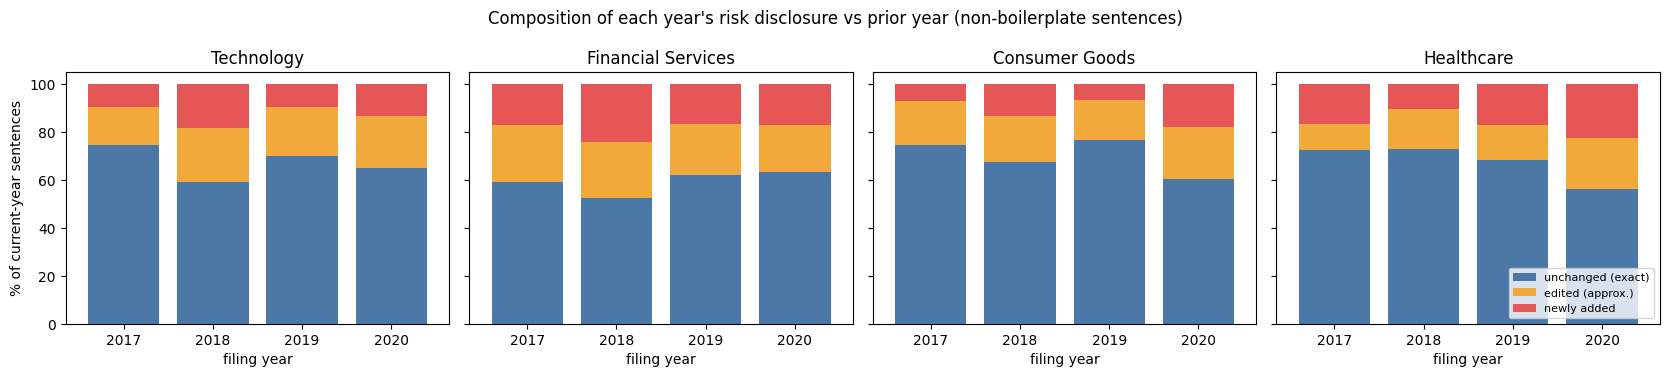

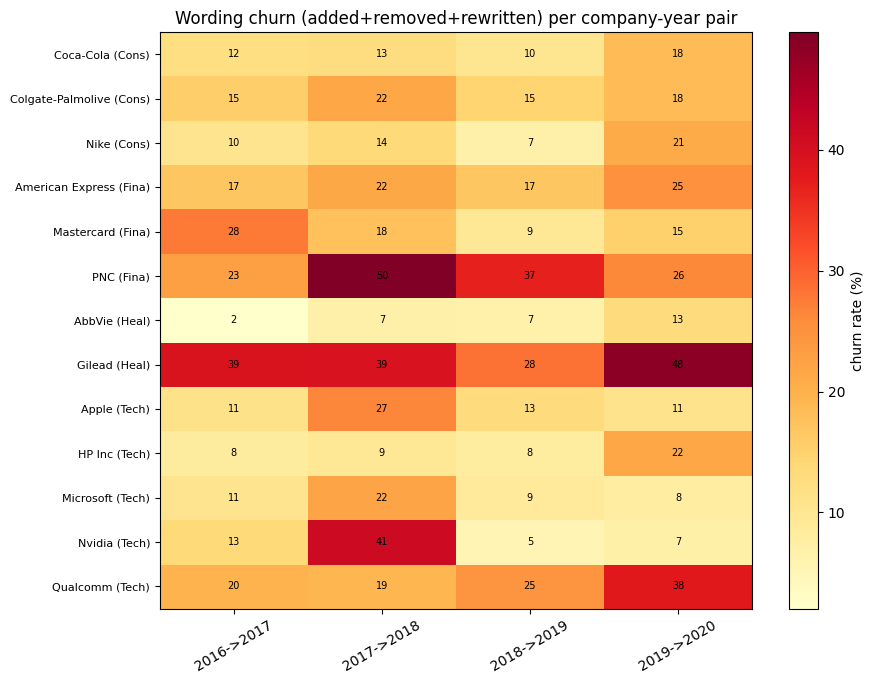

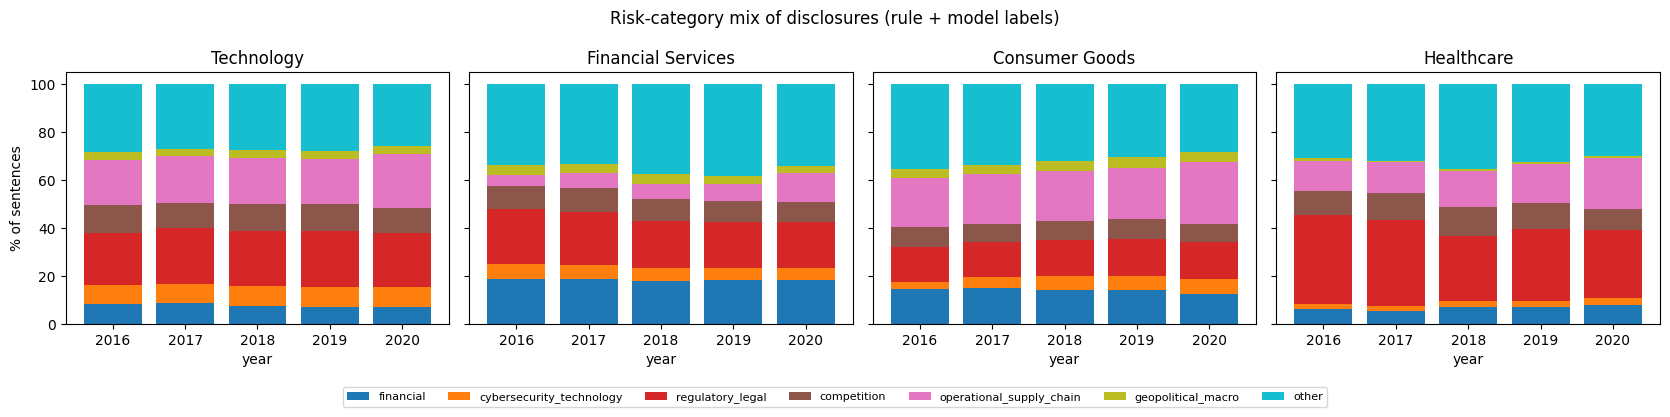

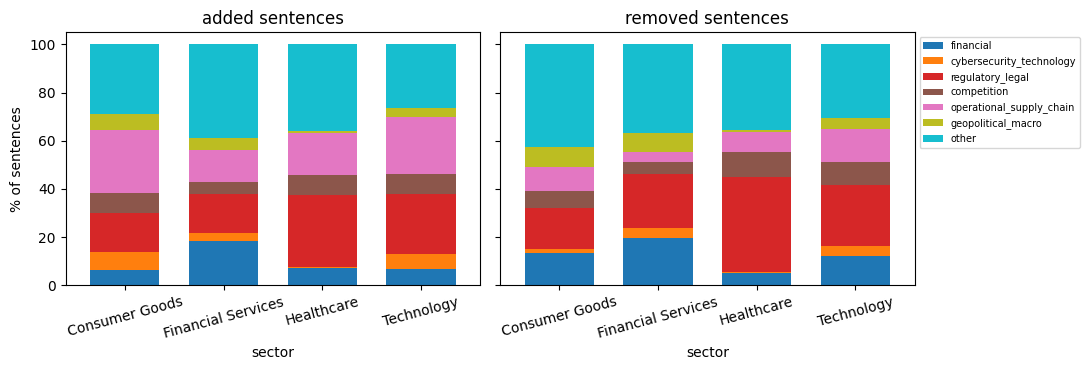

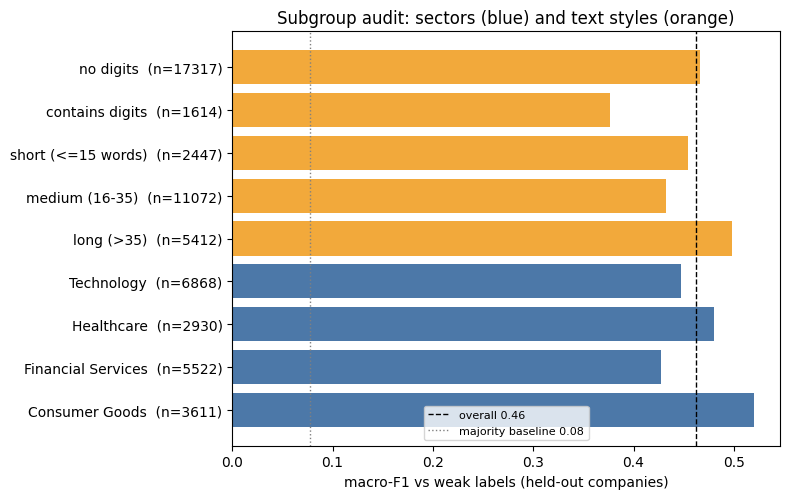

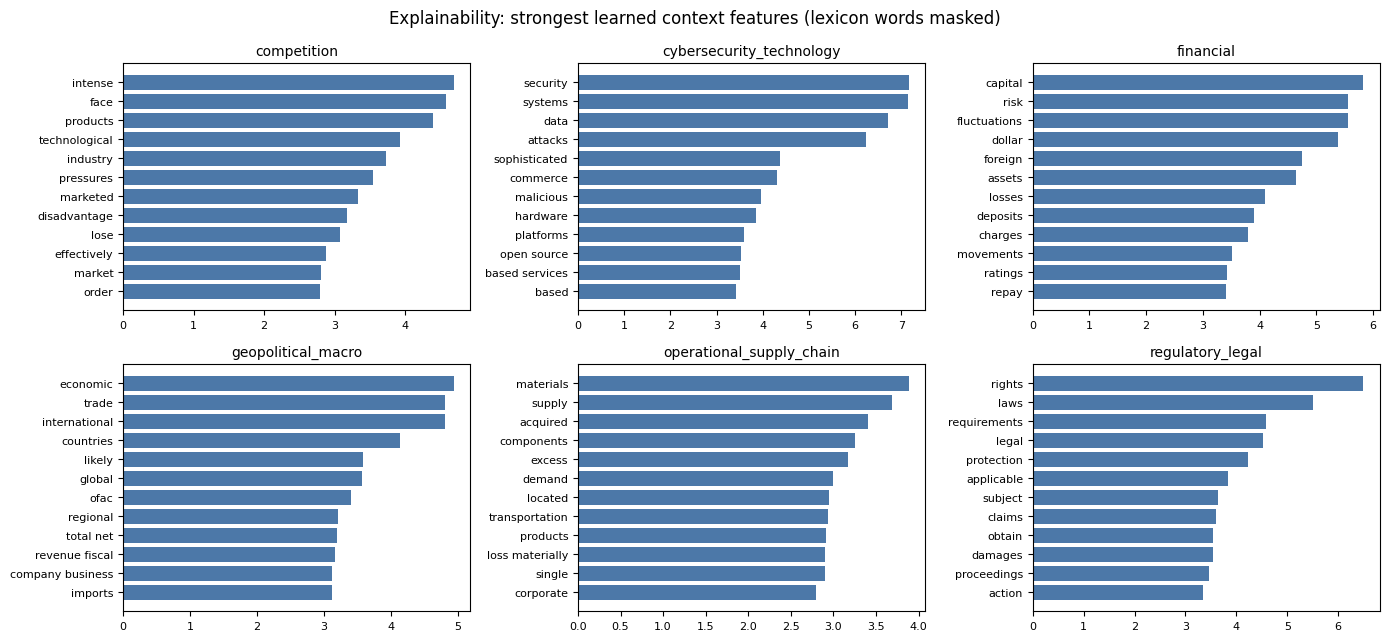

Figures saved. Annotation sample with 120 rows written to annotation_sample.csv


In [ ]:
# ============================================================
# CELL 6 - INDUSTRY / YEAR COMPARISON, VISUALISATIONS, EXPORTS, ANNOTATION SAMPLE
# ============================================================
from scipy.stats import kruskal
CAT_ORDER = CATS + ["other"]
yoy_df["period"] = yoy_df.year_prev.astype(str) + "->" + yoy_df.year_curr.astype(str)

# ---- industry x year summary + simple significance check ----
ind_year = (yoy_df.groupby(["sector", "year_curr"])[["pct_unchanged", "pct_edited", "pct_added", "pct_removed", "churn_rate", "doc_cosine", "n_curr"]]
            .mean().round(2).reset_index())
ind_year.to_csv(OUT / "industry_year_summary.csv", index=False)
groups_ = [g.churn_rate.values for _, g in yoy_df.groupby("sector") if len(g) >= 3]
if len(groups_) >= 2:
    H, p = kruskal(*groups_)
    print(f"Kruskal-Wallis test of churn_rate across sectors: H={H:.2f}, p={p:.3f} "
          f"(n={len(yoy_df)} company-year pairs; pairs of one company are NOT independent -> treat p as descriptive only)")
display(yoy_df.groupby("sector")[["pct_unchanged", "pct_added", "pct_removed", "churn_rate", "doc_cosine"]].mean().round(2))

cat_share = (sent_df[~sent_df.is_boilerplate].groupby(["sector", "year", "category"]).size()
             .groupby(level=[0, 1]).transform(lambda x: 100 * x / x.sum()).rename("share_pct").reset_index())
cat_share.round(2).to_csv(OUT / "category_share_by_sector_year.csv", index=False)
chg_cat = (changes_df[changes_df.change_type.isin(["added", "removed", "rewritten"])]
           .groupby(["sector", "change_type", "category"]).size().rename("n").reset_index())
chg_cat.to_csv(OUT / "changes_by_category.csv", index=False)

# export the main evidence table (original passages for analyst review)
changes_df.drop(columns=["sentence_id", "mate_id"]).to_csv(OUT / "sentence_changes.csv", index=False)
top_review = (changes_df[changes_df.change_type.isin(["added", "removed", "rewritten"])]
              .assign(review_priority=lambda d: 1 - d.similarity)
              .sort_values("review_priority", ascending=False).groupby(["company", "year_curr"]).head(5))
top_review.drop(columns=["sentence_id", "mate_id"]).to_csv(OUT / "top_changes_for_review.csv", index=False)

# ---- Figure 1: composition of year-over-year change by sector ----
fig, ax = plt.subplots(1, len(SECTORS), figsize=(4.2 * len(SECTORS), 3.8), sharey=True)
ax = np.atleast_1d(ax)
for a, s in zip(ax, SECTORS):
    d = yoy_df[yoy_df.sector == s].groupby("year_curr")[["pct_unchanged", "pct_edited", "pct_added"]].mean()
    if d.empty: a.set_title(f"{s}\n(no data)"); continue
    d.plot(kind="bar", stacked=True, ax=a, legend=False, color=["#4c78a8", "#f2a93b", "#e45756"], width=.8)
    a.set_title(s); a.set_xlabel("filing year"); a.tick_params(axis="x", rotation=0)
ax[0].set_ylabel("% of current-year sentences"); ax[-1].legend(["unchanged (exact)", "edited (approx.)", "newly added"], fontsize=8, loc="lower right")
fig.suptitle("Composition of each year's risk disclosure vs prior year (non-boilerplate sentences)")
savefig("fig1_change_composition_by_sector.png")

# ---- Figure 2: churn heatmap company x period ----
pv = yoy_df.pivot_table(index=["sector", "company"], columns="period", values="churn_rate")
fig, ax = plt.subplots(figsize=(1.3 * pv.shape[1] + 4, 0.38 * len(pv) + 2))
im = ax.imshow(pv.values, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(pv.shape[1])); ax.set_xticklabels(pv.columns, rotation=30)
ax.set_yticks(range(len(pv))); ax.set_yticklabels([f"{c} ({s[:4]})" for s, c in pv.index], fontsize=8)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        if not np.isnan(pv.values[i, j]): ax.text(j, i, f"{pv.values[i, j]:.0f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, label="churn rate (%)"); ax.set_title("Wording churn (added+removed+rewritten) per company-year pair")
savefig("fig2_churn_heatmap.png")

# ---- Figure 3: category share by sector and year ----
fig, ax = plt.subplots(1, len(SECTORS), figsize=(4.2 * len(SECTORS), 3.8), sharey=True)
ax = np.atleast_1d(ax)
for a, s in zip(ax, SECTORS):
    d = cat_share[cat_share.sector == s].pivot(index="year", columns="category", values="share_pct").reindex(columns=CAT_ORDER).fillna(0)
    if d.empty: a.set_title(f"{s}\n(no data)"); continue
    d.plot(kind="bar", stacked=True, ax=a, legend=False, width=.8, colormap="tab10"); a.set_title(s); a.tick_params(axis="x", rotation=0)
ax[0].set_ylabel("% of sentences"); h, l = ax[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=7, fontsize=8, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Risk-category mix of disclosures (rule + model labels)"); savefig("fig3_category_share_by_sector_year.png")

# ---- Figure 4: what kinds of risks are ADDED vs REMOVED, by sector ----
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, ct in zip(ax, ["added", "removed"]):
    d = chg_cat[chg_cat.change_type == ct].pivot(index="sector", columns="category", values="n").reindex(columns=CAT_ORDER).fillna(0)
    d = d.div(d.sum(1).replace(0, np.nan), axis=0).mul(100)
    d.plot(kind="bar", stacked=True, ax=a, legend=False, width=.7, colormap="tab10"); a.set_title(f"{ct} sentences"); a.tick_params(axis="x", rotation=15)
ax[0].set_ylabel("% of sentences"); ax[1].legend(fontsize=7, bbox_to_anchor=(1, 1)); savefig("fig4_added_vs_removed_categories.png")

# ---- Figure 5: audit (subgroup macro-F1) and Figure 6: explainability ----
sg = subgroup_df[subgroup_df.subgroup_type.isin(["sector", "style_length", "style_numbers"])]
fig, ax = plt.subplots(figsize=(8, 0.4 * len(sg) + 1.5))
ax.barh(sg.group + "  (n=" + sg.n.astype(str) + ")", sg.macro_f1, color=["#4c78a8" if t == "sector" else "#f2a93b" for t in sg.subgroup_type])
ax.axvline(overall["macro_f1"], color="k", ls="--", lw=1, label=f"overall {overall['macro_f1']:.2f}")
ax.axvline(base["macro_f1"], color="grey", ls=":", lw=1, label=f"majority baseline {base['macro_f1']:.2f}")
ax.set_xlabel("macro-F1 vs weak labels (held-out companies)"); ax.set_title("Subgroup audit: sectors (blue) and text styles (orange)"); ax.legend(fontsize=8)
savefig("fig5_subgroup_audit.png")

cats6 = [c for c in CLASSES if c != "other"]
fig, ax = plt.subplots(2, 3, figsize=(14, 6.5)); ax = ax.ravel()
for a, c in zip(ax, cats6):
    d = top_feat_df[top_feat_df.category == c].sort_values("coefficient")
    a.barh(d.feature, d.coefficient, color="#4c78a8"); a.set_title(c, fontsize=10); a.tick_params(labelsize=8)
for a in ax[len(cats6):]: a.axis("off")
fig.suptitle("Explainability: strongest learned context features (lexicon words masked)"); savefig("fig6_top_features.png")

# ---- annotation sample for HUMAN validation (no fake ground truth is generated) ----
cand = changes_df[changes_df.change_type.isin(["added", "removed", "rewritten"])]
per_cell = max(2, math.ceil(120 / max(1, cand.groupby(["sector", "change_type"]).ngroups)))
ann = pd.concat([d.sample(min(len(d), per_cell), random_state=SEED) for _, d in cand.groupby(["sector", "change_type"])])
ann = ann.sample(frac=1, random_state=SEED).reset_index(drop=True)
ann.insert(0, "annotation_id", range(1, len(ann) + 1))
ann = ann[["annotation_id", "sector", "company", "year_prev", "year_curr", "change_type", "similarity", "prev_text", "curr_text",
           "category", "category_source"]].rename(columns={"category": "auto_category", "category_source": "auto_category_source"})
ann["human_category"] = ""; ann["human_material_change"] = ""; ann["notes"] = ""
ann.to_csv(OUT / "annotation_sample.csv", index=False)
(OUT / "ANNOTATION_INSTRUCTIONS.md").write_text(f"""# Human annotation instructions (about 30-45 minutes for {len(ann)} rows)
1. Download `annotation_sample.csv`, open in Excel/Sheets.
2. `human_category` - the main risk topic of the sentence that carries the change
   (`curr_text` for added/rewritten, `prev_text` for removed). Allowed values:
   {', '.join(CATS)}, other. Judge the sentence, NOT the auto label (try not to look at auto_category first).
3. `human_material_change` - would a financial analyst consider this change worth reviewing? y / n / unsure.
   Judge ONLY the disclosure wording, not the company's real-world risk.
4. Save as `annotation_sample_filled.csv` and upload it to `{OUT}/`, then re-run Cell 7.
   Do not edit other columns. Leave a cell blank if you cannot decide.
""")
print(f"Figures saved. Annotation sample with {len(ann)} rows written to annotation_sample.csv")

### Cell 7 - Model card, pitch outline and file summary
All numbers in the model card are computed from this run. If you fill the annotation file and re-run this cell, human-validated metrics are added automatically.

In [ ]:
# ============================================================
# CELL 7 - OPTIONAL HUMAN-LABEL SCORING, MODEL CARD, PITCH OUTLINE, FILE SUMMARY
# ============================================================
# ---- optional: score against YOUR manual labels (only if you filled the annotation file) ----
human_txt = "Not yet performed. Fill `annotation_sample.csv`, save as `annotation_sample_filled.csv` in the output folder and re-run this cell."
filled = OUT / "annotation_sample_filled.csv"
if filled.exists():
    h = pd.read_csv(filled).fillna("")
    hc = h[h.human_category.astype(str).str.strip().isin(CATS + ["other"])]
    if len(hc) >= 20:
        labs = sorted(set(hc.human_category))
        acc = accuracy_score(hc.human_category, hc.auto_category)
        mf1 = f1_score(hc.human_category, hc.auto_category, labels=labs, average="macro", zero_division=0)
        by_sec = hc.groupby("sector").apply(lambda d: accuracy_score(d.human_category, d.auto_category)).round(3).to_dict()
        hm = h[h.human_material_change.astype(str).str.lower().isin(["y", "n"])]
        prec = hm.groupby("change_type").human_material_change.apply(lambda s: (s.str.lower() == "y").mean()).round(3).to_dict()
        human_txt = (f"Scored on {len(hc)} human-labelled changed sentences: category accuracy={acc:.3f}, macro-F1={mf1:.3f}; "
                     f"accuracy by sector={by_sec}. Share of flagged changes judged worth reviewing (y) by change type "
                     f"(n={len(hm)}): {prec}.")
        json.dump({"n": len(hc), "accuracy": acc, "macro_f1": mf1, "by_sector": by_sec, "review_precision": prec}, open(OUT / "human_eval_results.json", "w"))
    else:
        human_txt = f"Annotation file found but only {len(hc)} valid human_category rows (need >= 20)."
print("Human validation:", human_txt)

# ---- numbers for the model card (all computed above - nothing typed in by hand) ----
sec_df = subgroup_df[subgroup_df.subgroup_type == "sector"].sort_values("macro_f1")
len_df = subgroup_df[subgroup_df.subgroup_type == "style_length"].sort_values("macro_f1")
gap_sec = sec_df.macro_f1.max() - sec_df.macro_f1.min()
gap_len = len_df.macro_f1.max() - len_df.macro_f1.min()
chg_counts = changes_df.change_type.value_counts().to_dict()
syn_txt = "; ".join(f"{k}: {v:.2f}" for k, v in syn_overall["recall"].items())
heavy_r = syn_overall.loc[role_names["heavy"], "recall"]
n_comp_by_sec = SAMPLE.groupby("sector").cik.nunique().to_dict()
top_terms = {c: ", ".join(top_feat_df[(top_feat_df.category == c) & (top_feat_df["rank"] <= 4)].feature) for c in CLASSES if c != "other"}
used_repl = [CIK_INFO[c][0] for c in SAMPLE.cik.unique() if CIK_INFO[c][2] == "replacement"]

MODEL_CARD = f"""# RiskLens - Model Card
**Task:** compare consecutive annual 10-K Item 1A (Risk Factors) texts and surface *wording changes* with evidence. **Not** a measure of real economic risk.

**Intended use:** triage tool for analysts/students - shows which risk sentences were added, removed or reworded between year t-1 and t, grouped by risk topic, with the original passages. Out of scope: investment decisions, materiality judgements, legal/compliance conclusions, firms or years outside the sample.

**Data:** `eloukas/edgar-corpus` (`section_1A`), filing years {WINDOW[0]}-{WINDOW[-1]}. Sample: {len(SAMPLE)} filings ({SAMPLE.cik.nunique()} companies; per sector {n_comp_by_sec}); original target was {TARGET} filings. Replacement companies used: {used_repl or 'none'}. Filings failing validation (empty / under {MIN_CHARS} characters / incorporated by reference) were never filled in or substituted from another year (see `availability_matrix.csv`). Years are the dataset's filing-year labels.

**Method.** (1) Clean text, rule-based sentence split, keep sentences of 8-250 words, de-duplicate within a filing. (2) Sentences identical (normalised) in >= {BOILER_MIN_COMPANIES} companies are flagged as boilerplate and excluded. (3) Per company and consecutive years: exact match -> unchanged; remaining sentences matched one-to-one by TF-IDF (1-2-gram) cosine similarity: >= {MINOR_MIN} minor edit, {REWRITE_MIN}-{MINOR_MIN} rewritten; no match >= {REWRITE_MIN} -> added / removed. (4) Risk category: keyword lexicon (6 categories) gives weak labels; a TF-IDF + logistic-regression model trained with the keywords masked labels the remaining sentences (confidence >= 0.5, else 'other').

**Evaluation.** *Change matcher* - synthetic test with known edits (recall): {syn_txt}. *Category model* - grouped cross-validation, entire companies held out, scored against the **weak** lexicon labels (not human truth): accuracy {overall['accuracy']:.3f}, macro-F1 {overall['macro_f1']:.3f} vs majority baseline macro-F1 {base['macro_f1']:.3f} (n={overall['n']:,}). *Human validation:* {human_txt}

**Subgroup audit.** Macro-F1 by sector ranges from {sec_df.macro_f1.min():.3f} ({sec_df.iloc[0].group}) to {sec_df.macro_f1.max():.3f} ({sec_df.iloc[-1].group}), gap {gap_sec:.3f}. By sentence length it ranges from {len_df.macro_f1.min():.3f} ({len_df.iloc[0].group}) to {len_df.macro_f1.max():.3f} ({len_df.iloc[-1].group}), gap {gap_len:.3f}. Full tables: `subgroup_audit.csv`, `company_level_f1.csv`. Differences are descriptive (few companies per sector, one sample).

**Explainability.** Top learned features per category (keywords masked): {'; '.join(f'{k}: {v}' for k, v in top_terms.items())}. Each labelled sentence also stores the lexicon keywords that fired. Inspect `top_features_per_category.csv`, `fig6_top_features.png`.

**Limitations & risks.** (a) No gold category labels: model scores measure agreement with a keyword lexicon, so they can overstate real accuracy; lexicon words are ambiguous ('employees', 'laws'). (b) Rule-based sentence splitting merges headings into sentences and can mis-split tables/abbreviations. (c) Low similarity = different wording, not materiality; relocation, reordering or paraphrase can look like add + remove; heavy rewrites (< {REWRITE_MIN} similarity) are missed as rewrites (synthetic heavy-rewrite recall {heavy_r:.2f}). (d) Large companies only, 10-K Item 1A only; banks sometimes incorporate risk factors by reference (excluded). (e) Counts shift with the similarity threshold (`threshold_sensitivity.csv`). (f) Risk of over-trust: do not present flagged changes as 'new risks' without reading the evidence passages.
"""
(OUT / "MODEL_CARD.md").write_text(MODEL_CARD)
display(Markdown(MODEL_CARD))

# ---- 5-minute pitch outline built from the real results ----
worst = sec_df.iloc[0]; best_ = sec_df.iloc[-1]
(OUT / "PITCH_OUTLINE.md").write_text(f"""# 5-minute pitch outline
1. Problem (45s): analysts re-read 10-Ks to see how risk disclosures changed. RiskLens finds changed sentences and shows the original text.
2. Approach (90s): EDGAR-CORPUS Item 1A -> sentences -> remove boilerplate -> exact + TF-IDF matching across years -> added/removed/rewritten -> risk category (lexicon + model).
3. Results (60s): {len(SAMPLE)} filings, {chg_counts}. Show fig1 / fig2 / fig4.
4. Audit finding (60s): category macro-F1 {overall['macro_f1']:.2f} vs baseline {base['macro_f1']:.2f}; best sector {best_.group} ({best_.macro_f1:.2f}), weakest {worst.group} ({worst.macro_f1:.2f}). Show fig5 + fig6.
5. Limitation (45s): labels are weak (keyword-derived) and wording change != material change; human sample ({human_txt[:60]}...).
""")

# ---- summary of generated files ----
DESCR = {
 "availability_matrix.csv": "status (ok / empty / too_short / not_in_year_split ...) for every company-year checked",
 "candidate_gaps.csv": "exact gaps of the ORIGINAL candidate companies", "sample_manifest.csv": "the final sample actually used",
 "filing_stats.csv": "sentences / boilerplate share per filing", "yoy_summary.csv": "per company-year pair counts, churn and document similarity",
 "sentence_changes.csv": "EVIDENCE table: every added/removed/rewritten/minor-edit sentence with original text and category",
 "top_changes_for_review.csv": "5 highest-novelty changes per company-year for quick reading",
 "sentences_categorized.csv.gz": "all sentences with category labels", "threshold_sensitivity.csv": "how counts change with the similarity threshold",
 "matcher_synthetic_eval.csv": "recall of the matcher on synthetic known edits (overall / sector / length)",
 "category_eval_overall.csv": "model vs majority baseline (weak labels)", "category_eval_per_class.csv": "per-category precision/recall/F1",
 "subgroup_audit.csv": "AUDIT: performance by sector, sentence length, digits, year", "company_level_f1.csv": "macro-F1 for each company",
 "top_features_per_category.csv": "EXPLAINABILITY: top coefficients", "industry_year_summary.csv": "industry x year comparison",
 "category_share_by_sector_year.csv": "risk-topic mix per sector-year", "changes_by_category.csv": "added/removed counts per category",
 "annotation_sample.csv": "sample for human labelling", "ANNOTATION_INSTRUCTIONS.md": "how to label it",
 "MODEL_CARD.md": "one-page model card", "PITCH_OUTLINE.md": "5-minute pitch outline"}
print("\nFILES CREATED in", OUT)
for f in sorted(OUT.glob("*")):
    if f.is_file(): print(f"  {f.name:<36} {DESCR.get(f.name, 'figure' if f.suffix == '.png' else '')}")
zp = OUT.parent / "risklens_outputs.zip"
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
    for f in OUT.glob("*"):
        if f.is_file(): z.write(f, f.name)
print(f"\nZipped everything to {zp}")
if DOWNLOAD_ZIP:
    from google.colab import files; files.download(str(zp))

Human validation: Not yet performed. Fill `annotation_sample.csv`, save as `annotation_sample_filled.csv` in the output folder and re-run this cell.


# RiskLens - Model Card
**Task:** compare consecutive annual 10-K Item 1A (Risk Factors) texts and surface *wording changes* with evidence. **Not** a measure of real economic risk.

**Intended use:** triage tool for analysts/students - shows which risk sentences were added, removed or reworded between year t-1 and t, grouped by risk topic, with the original passages. Out of scope: investment decisions, materiality judgements, legal/compliance conclusions, firms or years outside the sample.

**Data:** `eloukas/edgar-corpus` (`section_1A`), filing years 2016-2020. Sample: 65 filings (13 companies; per sector {'Consumer Goods': 3, 'Financial Services': 3, 'Healthcare': 2, 'Technology': 5}); original target was 120 filings. Replacement companies used: ['Apple', 'Qualcomm', 'Nvidia', 'HP Inc', 'American Express', 'PNC', 'Colgate-Palmolive', 'Gilead']. Filings failing validation (empty / under 3000 characters / incorporated by reference) were never filled in or substituted from another year (see `availability_matrix.csv`). Years are the dataset's filing-year labels.

**Method.** (1) Clean text, rule-based sentence split, keep sentences of 8-250 words, de-duplicate within a filing. (2) Sentences identical (normalised) in >= 3 companies are flagged as boilerplate and excluded. (3) Per company and consecutive years: exact match -> unchanged; remaining sentences matched one-to-one by TF-IDF (1-2-gram) cosine similarity: >= 0.9 minor edit, 0.6-0.9 rewritten; no match >= 0.6 -> added / removed. (4) Risk category: keyword lexicon (6 categories) gives weak labels; a TF-IDF + logistic-regression model trained with the keywords masked labels the remaining sentences (confidence >= 0.5, else 'other').

**Evaluation.** *Change matcher* - synthetic test with known edits (recall): foreign sentence (should be 'added'): 1.00; dropped sentence (should be 'removed'): 1.00; heavy rewrite (should be matched): 0.55; light edit (should be matched): 0.87; unchanged (should match exactly): 1.00. *Category model* - grouped cross-validation, entire companies held out, scored against the **weak** lexicon labels (not human truth): accuracy 0.525, macro-F1 0.463 vs majority baseline macro-F1 0.078 (n=18,931). *Human validation:* Not yet performed. Fill `annotation_sample.csv`, save as `annotation_sample_filled.csv` in the output folder and re-run this cell.

**Subgroup audit.** Macro-F1 by sector ranges from 0.427 (Financial Services) to 0.520 (Consumer Goods), gap 0.093. By sentence length it ranges from 0.432 (medium (16-35)) to 0.498 (long (>35)), gap 0.066. Full tables: `subgroup_audit.csv`, `company_level_f1.csv`. Differences are descriptive (few companies per sector, one sample).

**Explainability.** Top learned features per category (keywords masked): competition: intense, face, products, technological; cybersecurity_technology: security, systems, data, attacks; financial: capital, fluctuations, risk, dollar; geopolitical_macro: economic, trade, international, countries; operational_supply_chain: materials, supply, acquired, components; regulatory_legal: rights, laws, requirements, legal. Each labelled sentence also stores the lexicon keywords that fired. Inspect `top_features_per_category.csv`, `fig6_top_features.png`.

**Limitations & risks.** (a) No gold category labels: model scores measure agreement with a keyword lexicon, so they can overstate real accuracy; lexicon words are ambiguous ('employees', 'laws'). (b) Rule-based sentence splitting merges headings into sentences and can mis-split tables/abbreviations. (c) Low similarity = different wording, not materiality; relocation, reordering or paraphrase can look like add + remove; heavy rewrites (< 0.6 similarity) are missed as rewrites (synthetic heavy-rewrite recall 0.55). (d) Large companies only, 10-K Item 1A only; banks sometimes incorporate risk factors by reference (excluded). (e) Counts shift with the similarity threshold (`threshold_sensitivity.csv`). (f) Risk of over-trust: do not present flagged changes as 'new risks' without reading the evidence passages.



FILES CREATED in /content/risklens_outputs
  ANNOTATION_INSTRUCTIONS.md           how to label it
  MODEL_CARD.md                        one-page model card
  PITCH_OUTLINE.md                     5-minute pitch outline
  annotation_sample.csv                sample for human labelling
  annotation_sample_claude_final.csv   
  availability_matrix.csv              status (ok / empty / too_short / not_in_year_split ...) for every company-year checked
  candidate_gaps.csv                   exact gaps of the ORIGINAL candidate companies
  category_eval_overall.csv            model vs majority baseline (weak labels)
  category_eval_per_class.csv          per-category precision/recall/F1
  category_share_by_sector_year.csv    risk-topic mix per sector-year
  changes_by_category.csv              added/removed counts per category
  company_level_f1.csv                 macro-F1 for each company
  fig1_change_composition_by_sector.png figure
  fig2_churn_heatmap.png               figure
  fig3_ca

### Final reliability audit
Run this after Cells 1–7. It checks internal consistency, confirms whether the original 120-filing target was actually achieved, and verifies that core outputs exist. Warnings are recorded rather than hidden. This audit does not claim real-world NLP accuracy without human-labelled evaluation.

In [ ]:
# ============================================================
# FINAL RELIABILITY AUDIT - RUN AFTER CELLS 1-7
# ============================================================
# These checks validate internal consistency and output generation.
# They do NOT establish real-world NLP accuracy; that requires human-labelled data.

from pathlib import Path
import json
import pandas as pd

audit_results = []

def audit_check(name, condition, detail):
    status = "PASS" if bool(condition) else "WARNING"
    audit_results.append({"check": name, "status": status, "detail": str(detail)})
    print(f"[{status}] {name}: {detail}")

# 1) The chosen sample should contain one usable filing per company-year.
expected_years = set(WINDOW)
sample_pairs = set(zip(SAMPLE["cik"].astype(str), SAMPLE["year"].astype(int)))
duplicate_pairs = int(SAMPLE.duplicated(["cik", "year"]).sum())
missing_years = []
for cik in SAMPLE["cik"].astype(str).unique():
    years_for_company = set(SAMPLE.loc[SAMPLE["cik"].astype(str) == cik, "year"].astype(int))
    if years_for_company != expected_years:
        missing_years.append((CIK_INFO.get(cik, (cik, "unknown", "unknown"))[0],
                              sorted(expected_years - years_for_company),
                              sorted(years_for_company - expected_years)))
audit_check("sample_has_no_duplicate_company_years", duplicate_pairs == 0,
            f"duplicate company-year rows={duplicate_pairs}")
audit_check("sample_year_coverage", len(missing_years) == 0,
            f"companies not covering every year in selected window={missing_years or 'none'}")

# 2) Preserve the original target explicitly; report gaps rather than silently claiming it was met.
sector_counts = SAMPLE.groupby("sector")["cik"].nunique().to_dict()
target_met = (len(SAMPLE) == TARGET and SAMPLE["cik"].nunique() == (len(SECTORS) * N_PER_SECTOR)
              and all(sector_counts.get(s, 0) == N_PER_SECTOR for s in SECTORS)
              and set(SAMPLE["year"].astype(int).unique()) == expected_years)
audit_check("original_target_sample", target_met,
            f"target={TARGET} filings; actual={len(SAMPLE)} filings / {SAMPLE['cik'].nunique()} companies; "
            f"companies per sector={sector_counts}; selected years={sorted(SAMPLE['year'].astype(int).unique())}")

# 3) Sentence and change table integrity.
audit_check("sentence_table_nonempty", len(sent_df) > 0, f"usable sentences={len(sent_df)}")
audit_check("change_table_has_expected_columns",
            {"change_type", "company", "sector", "year_curr", "prev_text", "curr_text", "similarity"}.issubset(changes_df.columns),
            f"columns present={sorted(changes_df.columns)}")
allowed_change_types = {"unchanged", "minor_edit", "rewritten", "added", "removed"}
unexpected_types = sorted(set(changes_df["change_type"].dropna().astype(str)) - allowed_change_types)
audit_check("change_types_valid", not unexpected_types, f"unexpected change types={unexpected_types or 'none'}")

# Similarity must be finite and within cosine-similarity bounds when present.
sim = pd.to_numeric(changes_df["similarity"], errors="coerce").dropna()
bad_sim = int(((sim < -1e-9) | (sim > 1.000001)).sum())
audit_check("similarity_values_in_range", bad_sim == 0,
            f"out-of-range non-null similarities={bad_sim}; non-null values checked={len(sim)}")

# 4) The synthetic matcher check should exist and contain results.
synthetic_file = OUT / "matcher_synthetic_eval.csv"
if synthetic_file.exists():
    syn_check = pd.read_csv(synthetic_file, index_col=0)
    audit_check("synthetic_matcher_evaluation_written", len(syn_check) > 0,
                f"rows in matcher_synthetic_eval.csv={len(syn_check)}")
else:
    audit_check("synthetic_matcher_evaluation_written", False,
                "matcher_synthetic_eval.csv not found; re-run Cell 4")

# 5) Check expected key deliverables without requiring optional human labels.
required_files = [
    "availability_matrix.csv", "sample_manifest.csv", "filing_stats.csv",
    "sentence_changes.csv", "top_changes_for_review.csv",
    "industry_year_summary.csv", "category_share_by_sector_year.csv",
    "changes_by_category.csv", "annotation_sample.csv", "MODEL_CARD.md", "PITCH_OUTLINE.md"
]
missing_files = [name for name in required_files if not (OUT / name).exists()]
audit_check("core_outputs_written", not missing_files,
            f"missing core output files={missing_files or 'none'}")

# Save audit even when warnings exist, so limitations are documented.
audit_df = pd.DataFrame(audit_results)
audit_df.to_csv(OUT / "reliability_audit.csv", index=False)
print("\\nReliability audit saved to:", OUT / "reliability_audit.csv")
print("Interpretation: PASS means an internal consistency check passed. WARNING means inspect the detail; "
      "it is not automatically a code failure.")
print("Accuracy limitation: synthetic tests measure known artificial edits; weak-label CV measures agreement "
      "with the keyword lexicon. Neither substitutes for human-labelled validation.")


[PASS] sample_has_no_duplicate_company_years: duplicate company-year rows=0
[PASS] sample_year_coverage: companies not covering every year in selected window=none
[WARNING] original_target_sample: target=120 filings; actual=65 filings / 13 companies; companies per sector={'Consumer Goods': 3, 'Financial Services': 3, 'Healthcare': 2, 'Technology': 5}; selected years=[np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020)]
[PASS] sentence_table_nonempty: usable sentences=20727
[PASS] change_table_has_expected_columns: columns present=['added_terms', 'all_categories', 'category', 'category_source', 'change_type', 'cik', 'company', 'curr_text', 'matched_keywords', 'mate_id', 'number_changed', 'prev_text', 'removed_terms', 'sector', 'sentence_id', 'signal_words_changed', 'similarity', 'year_curr', 'year_prev']
[PASS] change_types_valid: unexpected change types=none
[PASS] similarity_values_in_range: out-of-range non-null similarities=0; non-null values checked=7989


In [ ]:
import os
import zipfile

out_dir = "/content/risklens_outputs"
zip_path = "/content/risklens_outputs.zip"

print("Output folder exists:", os.path.isdir(out_dir))
print("ZIP exists:", os.path.isfile(zip_path))

if os.path.isfile(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        bad_file = z.testzip()
        print("ZIP integrity:", "OK" if bad_file is None else f"Problem: {bad_file}")
        print("Files in ZIP:", len(z.namelist()))

Output folder exists: True
ZIP exists: True
ZIP integrity: OK
Files in ZIP: 29


In [ ]:

import pandas as pd
from pathlib import Path

out = Path("/content/risklens_outputs")
file = out / "annotation_sample_claude_final.csv"

df = pd.read_csv(file)

print("Rows:", len(df))
print("\nColumns:")
print(df.columns.tolist())

print("\nReview status:")
print(df["review_status"].value_counts(dropna=False))

print("\nSuggested categories:")
print(df["suggested_human_category"].value_counts(dropna=False))

print("\nMaterial-change suggestions:")
print(df["suggested_human_material_change"].value_counts(dropna=False))


Rows: 120

Columns:
['annotation_id', 'sector', 'company', 'year_prev', 'year_curr', 'change_type', 'similarity', 'prev_text', 'curr_text', 'auto_category', 'auto_category_source', 'human_category', 'human_material_change', 'notes', 'suggested_human_category', 'suggested_human_material_change', 'suggestion_notes', 'review_status']

Review status:
review_status
SUGGESTED          118
REVIEW REQUIRED      2
Name: count, dtype: int64

Suggested categories:
suggested_human_category
regulatory_legal            34
other                       24
operational_supply_chain    22
financial                   16
geopolitical_macro           9
cybersecurity_technology     8
competition                  7
Name: count, dtype: int64

Material-change suggestions:
suggested_human_material_change
n    74
y    46
Name: count, dtype: int64


In [ ]:

print("Existing human category labels:")
print(df["human_category"].value_counts(dropna=False).head(15))

print("\nExisting human material-change labels:")
print(df["human_material_change"].value_counts(dropna=False))

print("\nRows with both original annotation fields filled:")
valid = (
    df["human_category"].notna()
    & df["human_category"].astype(str).str.strip().ne("")
    & df["human_material_change"].notna()
    & df["human_material_change"].astype(str).str.strip().ne("")
)
print(valid.sum(), "out of", len(df))


Existing human category labels:
human_category
NaN    120
Name: count, dtype: int64

Existing human material-change labels:
human_material_change
NaN    120
Name: count, dtype: int64

Rows with both original annotation fields filled:
0 out of 120


In [ ]:

from pathlib import Path
import pandas as pd

out = Path("/content/risklens_outputs")
df = pd.read_csv(out / "annotation_sample_claude_final.csv")

summary = f"""# RiskLens Annotation Review Summary

## Dataset
- Annotation rows: {len(df)}
- Suggested categories: {df['suggested_human_category'].nunique()}
- Rows marked SUGGESTED: {(df['review_status'] == 'SUGGESTED').sum()}
- Rows marked REVIEW REQUIRED: {(df['review_status'] == 'REVIEW REQUIRED').sum()}

## Suggested material-change labels
{df['suggested_human_material_change'].value_counts().to_string()}

## Suggested categories
{df['suggested_human_category'].value_counts().to_string()}

## Evaluation limitation
The category and material-change labels were generated through automated
review by Claude. No human reference labels were available in the 120-row
sample. Therefore, these suggestions must not be treated as ground truth,
and accuracy or human agreement cannot be calculated from this file.

The suggestions are exploratory and may contain errors, particularly for
unrelated sentence pairs, fragments, and low-confidence comparisons.
"""

path = out / "ANNOTATION_REVIEW_SUMMARY.md"
path.write_text(summary, encoding="utf-8")
print("Saved:", path)
print(summary)


Saved: /content/risklens_outputs/ANNOTATION_REVIEW_SUMMARY.md
# RiskLens Annotation Review Summary

## Dataset
- Annotation rows: 120
- Suggested categories: 7
- Rows marked SUGGESTED: 118
- Rows marked REVIEW REQUIRED: 2

## Suggested material-change labels
suggested_human_material_change
n    74
y    46

## Suggested categories
suggested_human_category
regulatory_legal            34
other                       24
operational_supply_chain    22
financial                   16
geopolitical_macro           9
cybersecurity_technology     8
competition                  7

## Evaluation limitation
The category and material-change labels were generated through automated
review by Claude. No human reference labels were available in the 120-row
sample. Therefore, these suggestions must not be treated as ground truth,
and accuracy or human agreement cannot be calculated from this file.

The suggestions are exploratory and may contain errors, particularly for
unrelated sentence pairs, fragments,

In [ ]:

from pathlib import Path

out = Path("/content/risklens_outputs")
model_card = out / "MODEL_CARD.md"
summary_file = out / "ANNOTATION_REVIEW_SUMMARY.md"

if not model_card.exists():
    print("MODEL_CARD.md not found. Check the folder before proceeding.")
else:
    card = model_card.read_text(encoding="utf-8")
    summary = summary_file.read_text(encoding="utf-8")

    heading = "## Automated Annotation Review"

    if heading in card:
        print("Annotation review section already exists. No changes made.")
    else:
        updated = card.rstrip() + "\n\n" + heading + "\n\n"
        updated += summary.split(
            "## Dataset", 1
        )[1].join(["## Dataset", ""]).strip() if False else ""
        updated = card.rstrip() + "\n\n" + heading + "\n\n"
        updated += (
            "Claude reviewed a 120-row annotation sample. "
            "118 rows were marked SUGGESTED and 2 were marked "
            "REVIEW REQUIRED. Suggested material-change labels were "
            "46 y and 74 n.\n\n"
            "These are automated suggestions, not human-verified labels. "
            "The sample contained no human reference labels, so model "
            "accuracy and agreement with human annotators cannot be "
            "calculated from these annotations. Some rows contain weak "
            "sentence matches, incomplete context, or low-confidence "
            "judgments. See ANNOTATION_REVIEW_SUMMARY.md for category "
            "counts and further limitations.\n"
        )
        model_card.write_text(updated, encoding="utf-8")
        print("Updated:", model_card)


Updated: /content/risklens_outputs/MODEL_CARD.md


In [ ]:

from pathlib import Path

out = Path("/content/risklens_outputs")

for name in ["MODEL_CARD.md", "PITCH_OUTLINE.md", "ANNOTATION_REVIEW_SUMMARY.md"]:
    path = out / name
    print(f"\n{'=' * 50}\n{name}\n{'=' * 50}")
    if path.exists():
        print(path.read_text(encoding="utf-8")[:7000])
    else:
        print("FILE NOT FOUND")



MODEL_CARD.md
# RiskLens - Model Card
**Task:** compare consecutive annual 10-K Item 1A (Risk Factors) texts and surface *wording changes* with evidence. **Not** a measure of real economic risk.

**Intended use:** triage tool for analysts/students - shows which risk sentences were added, removed or reworded between year t-1 and t, grouped by risk topic, with the original passages. Out of scope: investment decisions, materiality judgements, legal/compliance conclusions, firms or years outside the sample.

**Data:** `eloukas/edgar-corpus` (`section_1A`), filing years 2016-2020. Sample: 65 filings (13 companies; per sector {'Consumer Goods': 3, 'Financial Services': 3, 'Healthcare': 2, 'Technology': 5}); original target was 120 filings. Replacement companies used: ['Apple', 'Qualcomm', 'Nvidia', 'HP Inc', 'American Express', 'PNC', 'Colgate-Palmolive', 'Gilead']. Filings failing validation (empty / under 3000 characters / incorporated by reference) were never filled in or substituted fro

In [ ]:

from pathlib import Path

out = Path("/content/risklens_outputs")

# Update MODEL_CARD.md
model_path = out / "MODEL_CARD.md"
model = model_path.read_text(encoding="utf-8")

old = (
    "**Human validation:** Not yet performed. Fill `annotation_sample.csv`, "
    "save as `annotation_sample_filled.csv` in the output folder and re-run this cell."
)

new = (
    "**Annotation review:** An automated review of 120 sampled rows was "
    "performed using Claude-generated suggestions. 118 rows were marked "
    "`SUGGESTED` and 2 `REVIEW REQUIRED`. No human reference labels were "
    "available; therefore, human validation and agreement with human "
    "annotators have not been measured. See `ANNOTATION_REVIEW_SUMMARY.md`."
)

if old in model:
    model = model.replace(old, new)
    model_path.write_text(model, encoding="utf-8")
    print("Updated MODEL_CARD.md")
else:
    print("Exact old sentence not found in MODEL_CARD.md. Check manually.")

# Update PITCH_OUTLINE.md
pitch_path = out / "PITCH_OUTLINE.md"
pitch = pitch_path.read_text(encoding="utf-8")

pitch = pitch.replace(
    "human sample (Not yet performed. Fill `annotation_sample.csv`, "
    "save as `an...",
    "automated annotation review: 120 suggestions, 118 marked SUGGESTED "
    "and 2 REVIEW REQUIRED; no human reference labels or human-validation "
    "accuracy available."
)

pitch_path.write_text(pitch, encoding="utf-8")
print("Saved PITCH_OUTLINE.md")

print("\nCheck the updated lines:")
for filename in ["MODEL_CARD.md", "PITCH_OUTLINE.md"]:
    print(f"\n--- {filename} ---")
    print((out / filename).read_text(encoding="utf-8")[-1800:])


Exact old sentence not found in MODEL_CARD.md. Check manually.
Saved PITCH_OUTLINE.md

Check the updated lines:

--- MODEL_CARD.md ---
hnology: security, systems, data, attacks; financial: capital, fluctuations, risk, dollar; geopolitical_macro: economic, trade, international, countries; operational_supply_chain: materials, supply, acquired, components; regulatory_legal: rights, laws, requirements, legal. Each labelled sentence also stores the lexicon keywords that fired. Inspect `top_features_per_category.csv`, `fig6_top_features.png`.

**Limitations & risks.** (a) No gold category labels: model scores measure agreement with a keyword lexicon, so they can overstate real accuracy; lexicon words are ambiguous ('employees', 'laws'). (b) Rule-based sentence splitting merges headings into sentences and can mis-split tables/abbreviations. (c) Low similarity = different wording, not materiality; relocation, reordering or paraphrase can look like add + remove; heavy rewrites (< 0.6 similarity

In [ ]:

from pathlib import Path

out = Path("/content/risklens_outputs")

# Clean up the pitch outline ending
pitch_path = out / "PITCH_OUTLINE.md"
pitch = pitch_path.read_text(encoding="utf-8").rstrip()

pitch = pitch.removesuffix("available.).").removesuffix("available).")
pitch_path.write_text(pitch + "\n", encoding="utf-8")

# Verify documentation
for filename in ["MODEL_CARD.md", "PITCH_OUTLINE.md"]:
    text = (out / filename).read_text(encoding="utf-8")
    print(f"\n{filename}")
    print("Exists:", True)
    print("Annotation review mentioned:", "annotation" in text.lower())
    print("Human-validation limitation mentioned:",
          "human reference labels" in text.lower()
          or "human validation" in text.lower())
    print("Last lines:\n", "\n".join(text.splitlines()[-5:]))



MODEL_CARD.md
Exists: True
Annotation review mentioned: True
Human-validation limitation mentioned: True
Last lines:
 ## Automated Annotation Review

Claude reviewed a 120-row annotation sample. 118 rows were marked SUGGESTED and 2 were marked REVIEW REQUIRED. Suggested material-change labels were 46 y and 74 n.

These are automated suggestions, not human-verified labels. The sample contained no human reference labels, so model accuracy and agreement with human annotators cannot be calculated from these annotations. Some rows contain weak sentence matches, incomplete context, or low-confidence judgments. See ANNOTATION_REVIEW_SUMMARY.md for category counts and further limitations.

PITCH_OUTLINE.md
Exists: True
Annotation review mentioned: True
Human-validation limitation mentioned: True
Last lines:
 1. Problem (45s): analysts re-read 10-Ks to see how risk disclosures changed. RiskLens finds changed sentences and shows the original text.
2. Approach (90s): EDGAR-CORPUS Item 1A -> sent

In [ ]:

from pathlib import Path
import zipfile

out = Path("/content/risklens_outputs")
zip_path = Path("/content/risklens_outputs_final.zip")

# Finish the pitch outline cleanly
pitch_path = out / "PITCH_OUTLINE.md"
pitch = pitch_path.read_text(encoding="utf-8").rstrip()
if not pitch.endswith("."):
    pitch += "."
pitch_path.write_text(pitch + "\n", encoding="utf-8")

# Package all current output files
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(out.rglob("*")):
        if p.is_file() and p != zip_path:
            z.write(p, p.relative_to(out.parent))

# Verify ZIP integrity
with zipfile.ZipFile(zip_path, "r") as z:
    bad_file = z.testzip()
    print("ZIP integrity:", "OK" if bad_file is None else f"Problem: {bad_file}")
    print("Files included:", len(z.namelist()))
    print("ZIP location:", zip_path)
    print("\nKey files:")
    for name in [
        "risklens_outputs/MODEL_CARD.md",
        "risklens_outputs/PITCH_OUTLINE.md",
        "risklens_outputs/ANNOTATION_REVIEW_SUMMARY.md",
        "risklens_outputs/annotation_sample_claude_final.csv",
    ]:
        print(name, "->", "Included" if name in z.namelist() else "Missing")


ZIP integrity: OK
Files included: 37
ZIP location: /content/risklens_outputs_final.zip

Key files:
risklens_outputs/MODEL_CARD.md -> Included
risklens_outputs/PITCH_OUTLINE.md -> Included
risklens_outputs/ANNOTATION_REVIEW_SUMMARY.md -> Included
risklens_outputs/annotation_sample_claude_final.csv -> Included


In [ ]:
from google.colab import files
files.download("/content/risklens_outputs_final.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## How to read the outputs
- **`sentence_changes.csv`**: the evidence. Each row is an added / removed / rewritten / minor-edit sentence with the original text of both years. Treat it as a reading list, not a verdict.
- **`yoy_summary.csv`, `fig1`, `fig2`**: share of unchanged / edited / added / removed sentences and churn per company-year.
- **`category_*`, `fig3`, `fig4`**: topic mix of disclosures and what kinds of risks are added vs removed.
- **`subgroup_audit.csv`, `fig5`**: audit across sectors and text styles. Scores are vs *weak* labels, not human truth.
- **`top_features_per_category.csv`, `fig6`**: explainability check.
- **`matcher_synthetic_eval.csv`**: recall of the matcher on edits we created ourselves.
- **`MODEL_CARD.md`, `PITCH_OUTLINE.md`**: assessment documents. **`availability_matrix.csv`, `candidate_gaps.csv`**: exactly which filings were unusable.